# PCB component detection: Experimental Setup and Results
## Reproducible figure workshop for the professor meeting - 6 November 2026

This notebook uses completed, frozen JSON evaluations and saved predictions. It
does not train a model or choose a new seed, confidence threshold, ensemble weight,
or checkpoint from test performance.

**Paper structure:** Introduction → Related Work → Method → Experimental Setup
and Results → Discussion/Limitations → Conclusion. We can draft the experimental
setup and evidence-backed results first. “Simulation” is less specific for these
experiments on real PCB photographs.

**Three scopes must remain distinct**

1. **Completed original-label study:** 543/77/41 image exports; six methods;
   seeds 0/1/2; shared square-640 evaluator. This is the principal quantitative
   comparison against our own retrained controls on the inherited split. A
   filename audit also finds three shared view-name aliases across these splits;
   this is not a certified board-disjoint generalization benchmark.
2. **Exploratory historical native-resolution study:** selected checkpoints,
   44 legacy test exports, WBF and a separate rectangular-batch ablation.
   The later label audit confirmed cross-split photograph overlap and annotation
   errors. These scores do not establish independent generalization.
3. **Reviewed r3 data:** annotation corrections and quarantined board families.
   Newly submitted models are pending; this notebook contains no r3 accuracy claim.

The examples in paper_images are layout references only. Their pictures and
numbers are not reused as our evidence. Every generated figure has a caption and
source hashes; PNG and editable SVG versions are written to paper/figures.

In [1]:
from pathlib import Path
import sys, json, hashlib, textwrap, platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyBboxPatch, Patch
from matplotlib.lines import Line2D
from PIL import Image
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "tools/paper_results_data.py").is_file())
sys.path.insert(0, str(ROOT))
from tools.paper_results_data import (
    CLASSES, METHODS, LABELS, COLORS, PRIMARY, NATIVE, SPEED, load, sha,
    prepare_tables, load_seed0_predictions, curves_and_checks, confusion,
    boxes_from_label, split_name_overlap,
)
FIG = ROOT / "paper/figures/meeting_20261106"
TAB = ROOT / "paper/tables/meeting_20261106"
MAN = ROOT / "paper/manuscript"
for directory in [FIG, TAB, MAN]:
    directory.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({
    "font.family": "DejaVu Serif", "font.size": 10,
    "axes.titlesize": 11, "axes.labelsize": 10,
    "figure.dpi": 120, "savefig.dpi": 300, "svg.fonttype": "none",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#5b6470", "grid.color": "#e1e5e9",
    "axes.titlepad": 12, "legend.frameon": False,
})
CLASS_COLORS = ["#168b8c", "#ba7241", "#8157a1", "#3976b0"]
T = prepare_tables(ROOT)
P = T["primary"]
GT, PRED = load_seed0_predictions(ROOT, T)
RAW = load(ROOT / PRIMARY / "metrics.json")
CURVES = {}
for method in METHODS:
    expected = next(r for r in RAW if r["model"] == method and r["seed"] == 0
                    and r["view"] == "common_ultralytics101" and r["split"] == "test")
    CURVES[method] = curves_and_checks(GT, PRED[method], expected)
print("Validated 18 seed records, 18 matching speed checkpoints, and six raw prediction caches.")
print("Reproduced all 24 seed-0 class AP50 values and fixed-confidence TP/FP counts.")
VIEW_OVERLAP=split_name_overlap(T["manifest"]["dataset"])
display(Markdown("**Split limitation:** the original-label filenames share these view aliases across splits: "
                 + ", ".join(VIEW_OVERLAP) + ". This grouping check is not a fresh pixel-level duplicate audit."))
FIGURES = []
SOURCES = [PRIMARY + "/metrics.json", PRIMARY + "/summary.json",
    PRIMARY + "/manifest.json", PRIMARY + "/raw_prediction_index.json",
    SPEED + "/benchmark.json", SPEED + "/checkpoint_parameter_counts.json",
    NATIVE + "/summary.json", "results/clean_main_test_v1/summary.json",
    "configs/info17_final_experiments.json", "tools/paper_results_data.py",
    "data_review/native1280_v2_20261106/patches_final_r3.json",
    "data_review/native1280_v2_20261106/audit/inventory.json"]
SOURCE_HASHES = {s: sha(ROOT / s) for s in SOURCES}
SOURCE_HASHES.update(load(ROOT / "paper/meeting_source_hashes.json"))
def style(ax, axis="y"):
    ax.grid(axis=axis, linewidth=.65, zorder=0)
    ax.set_axisbelow(True)
def save_figure(fig, name, title, caption, scope):
    if scope.startswith(("Original-label", "Shared original-label")):
        scope += " Inherited split; no board-disjoint generalization claim."
    fig.text(.01, .008, textwrap.fill(scope, 150), fontsize=8,
             color="#475569", va="bottom")
    fig.savefig(FIG / (name + ".png"), bbox_inches="tight", facecolor="white")
    fig.savefig(FIG / (name + ".svg"), bbox_inches="tight", facecolor="white")
    FIGURES.append(dict(id=name, title=title, caption=caption, scope=scope,
                        png=str((FIG / (name+".png")).relative_to(ROOT)),
                        svg=str((FIG / (name+".svg")).relative_to(ROOT))))
    display(fig)
    display(Markdown("**Caption.** " + caption))
    plt.close(fig)
def percent_table(df):
    result=df.copy()
    for c in result.columns:
        if c.startswith(("mAP", "precision", "recall", "f1")):
            result[c] = result[c] * 100
    return result
def export_table(df, name):
    df.to_csv(TAB / (name+".csv"), float_format="%.8f")
    (TAB / (name+".tex")).write_text(df.to_latex(escape=True,float_format=lambda v:f"{v:.2f}"))
export_table(percent_table(P), "primary_original640")
export_table(T["classes"], "primary_per_class_per_seed_fractions")
export_table(T["seeds"], "primary_per_seed_fractions")
export_table(T["native"], "legacy_native1280_fractions")
export_table(T["ablation"], "legacy_loss_ablation_percent")
display(percent_table(P[["mAP50_mean","mAP50_std","mAP50_95_mean",
                        "precision_mean","recall_mean","f1_mean","latency_ms_mean"]]).round(2))

Validated 18 seed records, 18 matching speed checkpoints, and six raw prediction caches.
Reproduced all 24 seed-0 class AP50 values and fixed-confidence TP/FP counts.


**Split limitation:** the original-label filenames share these view aliases across splits: arduinomega_top, duetwifi_bottom, duetwifi_top. This grouping check is not a fresh pixel-level duplicate audit.

,mAP50_mean,mAP50_std,mAP50_95_mean,precision_mean,recall_mean,f1_mean,latency_ms_mean
model,,,,,,,
yolov8s,52.34,1.38,38.33,61.45,24.04,34.55,6.27
yolov12s,53.61,2.39,38.44,62.39,24.58,35.20,9.92
yolo26s,49.94,1.85,35.03,60.51,24.75,35.04,7.77
yolo26s_agwd_sdice,53.23,1.40,37.77,58.97,25.18,35.25,7.77
physot_yolo26s,52.27,1.79,37.60,56.87,26.29,35.93,11.78
yolo26s_crop_specialist,55.08,0.89,39.62,59.45,25.84,35.99,7.70


## 1. Study design and model recipes
This is a component-level schematic, not an invented layer-by-layer network graph.

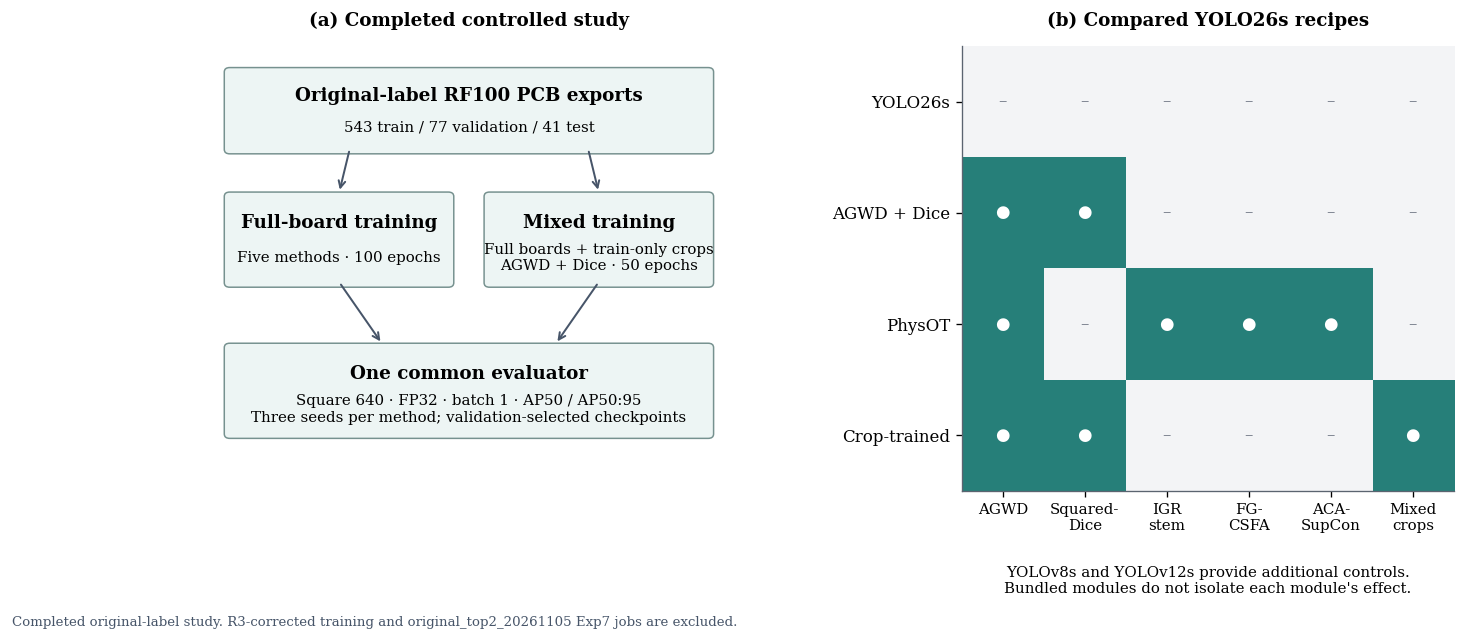

**Caption.** The completed original-label experiment compares six methods across three seeds. The crop method changes training sampling; all methods use a single full-board pass during common evaluation. Module indicators describe recipe differences and are not an isolated module ablation.

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.7), gridspec_kw={"width_ratios":[1.1,1]})
ax=axes[0];ax.set_axis_off();ax.set_xlim(0,1);ax.set_ylim(0,1)
def box(x,y,w,h,title,body,fill="#edf5f4"):
    ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle="round,pad=.012,rounding_size=.01",
                              facecolor=fill,edgecolor="#76918f",linewidth=.9))
    ax.text(x+w/2,y+h*.70,title,ha="center",va="center",fontsize=11,fontweight="bold")
    ax.text(x+w/2,y+h*.28,body,ha="center",va="center",fontsize=9)
box(.06,.77,.88,.17,"Original-label RF100 PCB exports","543 train / 77 validation / 41 test")
box(.06,.47,.40,.19,"Full-board training","Five methods · 100 epochs")
box(.54,.47,.40,.19,"Mixed training","Full boards + train-only crops\nAGWD + Dice · 50 epochs")
box(.06,.13,.88,.19,"One common evaluator","Square 640 · FP32 · batch 1 · AP50 / AP50:95\nThree seeds per method; validation-selected checkpoints")
for a,b in [((.28,.77),(.26,.67)),((.72,.77),(.74,.67)),
            ((.26,.47),(.34,.33)),((.74,.47),(.66,.33))]:
    ax.annotate("",xy=b,xytext=a,arrowprops=dict(arrowstyle="->",color="#475569",lw=1.2))
ax.set_title("(a) Completed controlled study",fontweight="bold")
flags=np.array([[0,0,0,0,0,0],[1,1,0,0,0,0],[1,0,1,1,1,0],[1,1,0,0,0,1]])
axes[1].imshow(flags,cmap=matplotlib.colors.ListedColormap(["#f3f4f6","#267f79"]),vmin=0,vmax=1,aspect="auto")
axes[1].set_yticks(range(4),["YOLO26s","AGWD + Dice","PhysOT","Crop-trained"])
axes[1].set_xticks(range(6),["AGWD","Squared-\nDice","IGR\nstem","FG-\nCSFA","ACA-\nSupCon","Mixed\ncrops"],fontsize=9)
for i in range(4):
    for j in range(6):axes[1].text(j,i,"●" if flags[i,j] else "–",ha="center",va="center",
                                   color="white" if flags[i,j] else "#6b7280")
axes[1].set_title("(b) Compared YOLO26s recipes",fontweight="bold")
axes[1].text(.5,-.23,"YOLOv8s and YOLOv12s provide additional controls.\nBundled modules do not isolate each module's effect.",
             transform=axes[1].transAxes,ha="center",fontsize=9)
fig.subplots_adjust(wspace=.43,bottom=.21,top=.86)
save_figure(fig,"01_study_design","Study design and model recipes",
    "The completed original-label experiment compares six methods across three seeds. "
    "The crop method changes training sampling; all methods use a single full-board pass during common evaluation. "
    "Module indicators describe recipe differences and are not an isolated module ablation.",
    "Completed original-label study. R3-corrected training and original_top2_20261105 Exp7 jobs are excluded.")

## 2. Dataset composition and component examples
Counts come from the frozen original-label manifest; they are not counts from the corrected r3 labels.

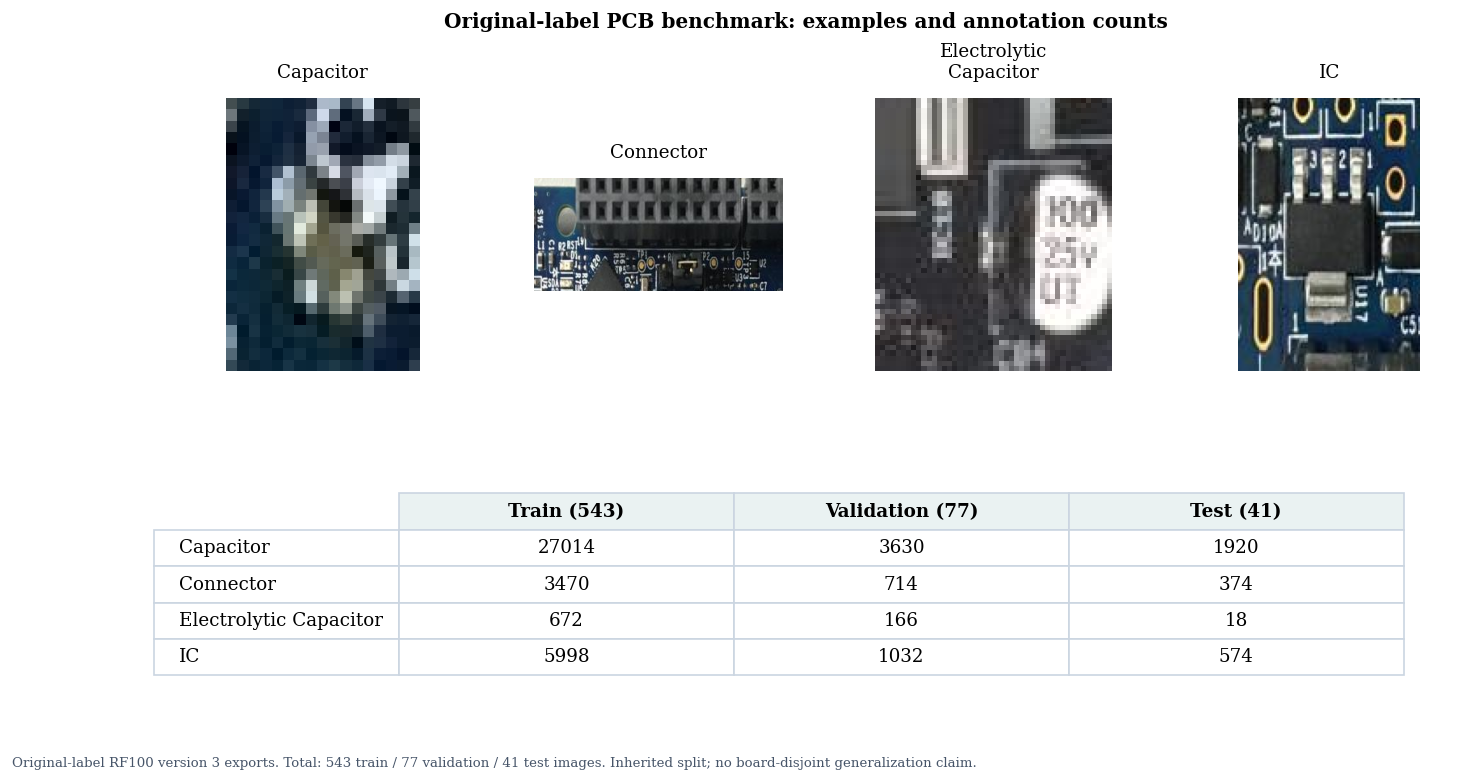

**Caption.** Four canonical component categories and original-export instance counts. Illustrative crops are the first test annotations, in recorded order, with a short side of at least eight pixels; they were not selected using detector performance. Existing original labels are preserved.

In [3]:
counts=pd.DataFrame({s:d["box_counts"] for s,d in T["manifest"]["dataset"]["splits"].items()}).reindex(CLASSES)
counts.columns=["Train (543)","Validation (77)","Test (41)"]
export_table(counts,"original640_class_counts")
fig=plt.figure(figsize=(13.5,6.5));gs=fig.add_gridspec(2,4,height_ratios=[1.2,1])
for c,name in enumerate(CLASSES):
    candidates=[(i,j) for i,g in enumerate(GT) for j,k in enumerate(g["cls"]) if k==c
                and np.min(g["boxes"][j,2:]-g["boxes"][j,:2])>=8]
    i,j=candidates[0];g=GT[i];b=g["boxes"][j];pad=max(4,.25*max(b[2:]-b[:2]))
    region=(max(0,b[0]-pad),max(0,b[1]-pad),min(640,b[2]+pad),min(640,b[3]+pad))
    im=Image.open(g["image"]).convert("RGB").crop(region)
    ax=fig.add_subplot(gs[0,c]);ax.imshow(im);ax.axis("off");ax.set_title(name.replace("Electrolytic ","Electrolytic\n"))
ax=fig.add_subplot(gs[1,:]);ax.axis("off")
table=ax.table(cellText=counts.values.astype(int),rowLabels=counts.index,
               colLabels=counts.columns,cellLoc="center",loc="center",bbox=[.16,.10,.80,.80])
table.auto_set_font_size(False);table.set_fontsize(11);table.scale(1,1.3)
for (i,j),cell in table.get_celld().items():
    cell.set_edgecolor("#cbd5e1")
    if i==0:cell.set_facecolor("#eaf2f2");cell.set_text_props(fontweight="bold")
fig.suptitle("Original-label PCB benchmark: examples and annotation counts",fontweight="bold",y=.98)
fig.subplots_adjust(top=.87,bottom=.10,hspace=.40,wspace=.35)
save_figure(fig,"02_dataset_examples_counts","Dataset examples and annotation counts",
    "Four canonical component categories and original-export instance counts. Illustrative crops are the "
    "first test annotations, in recorded order, with a short side of at least eight pixels; they were not "
    "selected using detector performance. Existing original labels are preserved.",
    "Original-label RF100 version 3 exports. Total: 543 train / 77 validation / 41 test images.")

## 3. Main quantitative comparison: all seeds, not the best seed
Error bars show sample standard deviation across three training seeds, not confidence intervals.

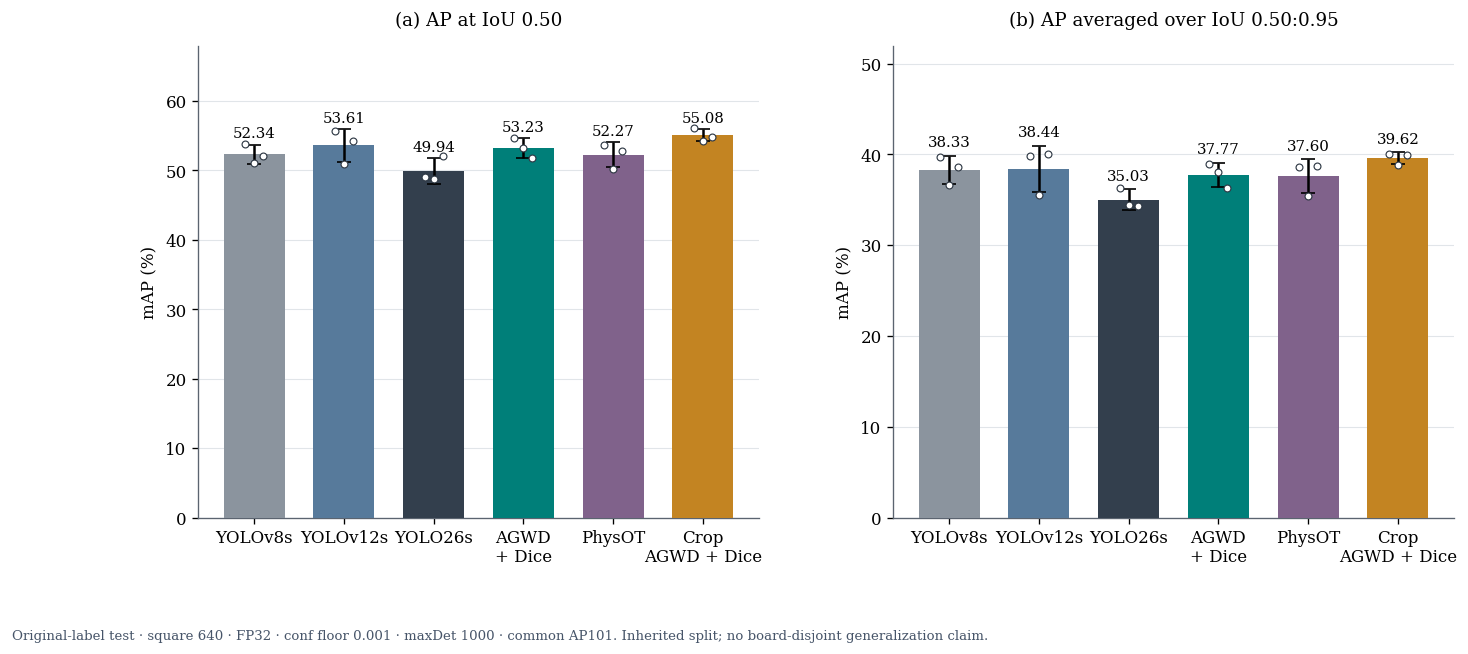

**Caption.** Mean and sample SD across seeds 0/1/2 on the 41-image original-label test split. Hollow markers show individual seeds. Each model is evaluated with the same common scorer and full-board input, including the crop-trained method. No significance claim is made from three seeds.

In [4]:
fig,axes=plt.subplots(1,2,figsize=(13.5,5.7))
short=["YOLOv8s","YOLOv12s","YOLO26s","AGWD\n+ Dice","PhysOT","Crop\nAGWD + Dice"]
x=np.arange(6)
for ax,metric,title,limit in zip(axes,["mAP50","mAP50_95"],["(a) AP at IoU 0.50","(b) AP averaged over IoU 0.50:0.95"],[68,52]):
    values=P[metric+"_mean"].values*100;sd=P[metric+"_std"].values*100
    ax.bar(x,values,color=[COLORS[m] for m in METHODS],width=.68,yerr=sd,capsize=4,zorder=3)
    for i,m in enumerate(METHODS):
        raw=T["seeds"].loc[T["seeds"].model==m,metric].values*100
        ax.scatter(i+np.array([-.10,0,.10]),raw,s=17,facecolors="white",edgecolors="#2f3945",zorder=5,lw=.7)
        ax.text(i,values[i]+sd[i]+1.0,f"{values[i]:.2f}",ha="center",fontsize=9)
    ax.set(xticks=x,xticklabels=short,ylim=(0,limit),ylabel="mAP (%)",title=title);style(ax)
fig.subplots_adjust(bottom=.19,top=.88,wspace=.24)
save_figure(fig,"03_primary_accuracy","Shared-protocol test accuracy",
    "Mean and sample SD across seeds 0/1/2 on the 41-image original-label test split. Hollow markers show "
    "individual seeds. Each model is evaluated with the same common scorer and full-board input, including "
    "the crop-trained method. No significance claim is made from three seeds.",
    "Original-label test · square 640 · FP32 · conf floor 0.001 · maxDet 1000 · common AP101.")

## 4. Per-class performance and operating precision/recall

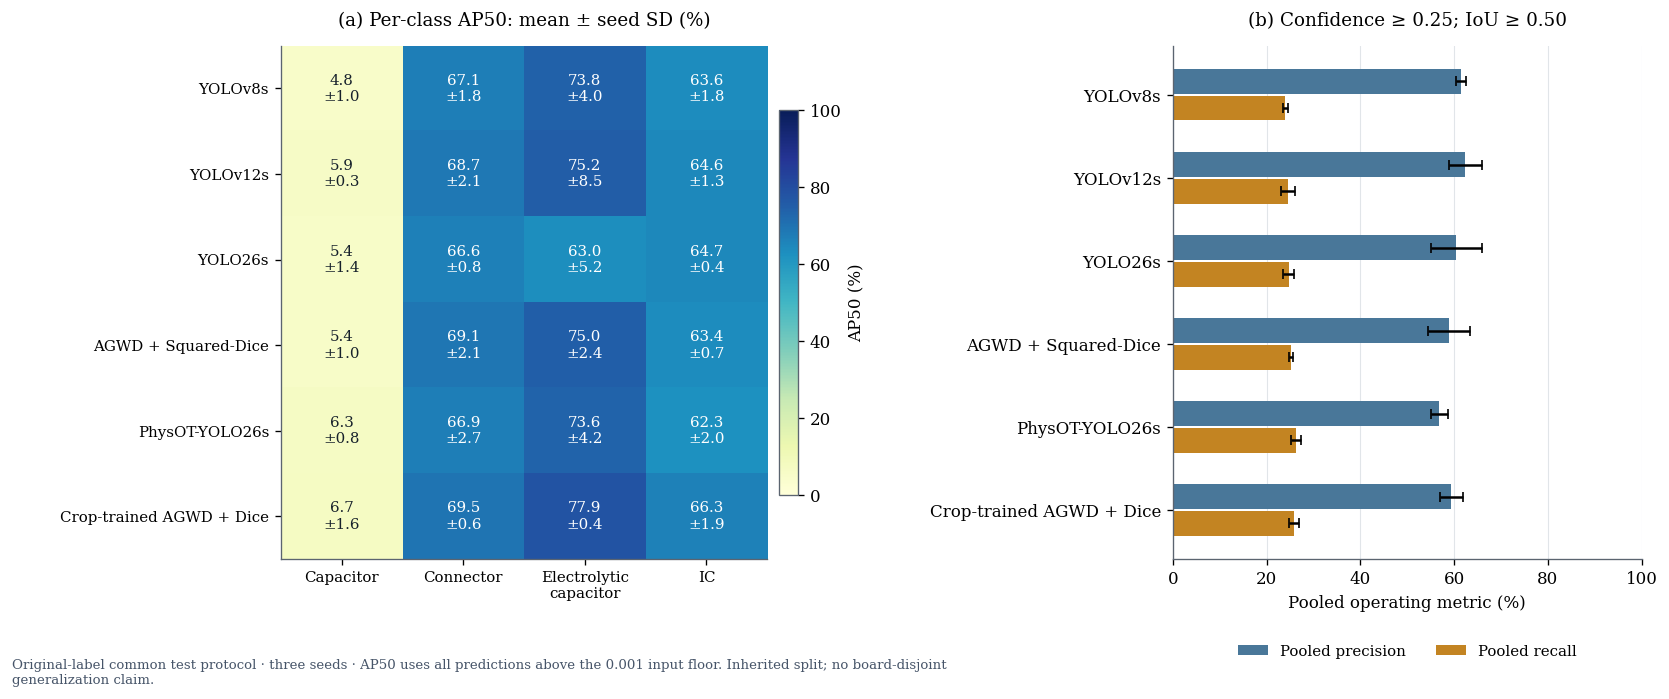

**Caption.** AP is averaged over three seeds. Pooled precision and recall are computed by summing class TP/FP/FN at confidence 0.25 and IoU 0.50 within each seed, then summarizing across seeds. They are not best-F1-threshold or macro-averaged P/R. The test split contains only 18 electrolytic annotations.

In [5]:
cm=T["classes"].groupby(["model","component"]).agg(ap50_mean=("ap50","mean"),ap50_std=("ap50","std"),
    precision_mean=("precision","mean"),recall_mean=("recall","mean")).reset_index()
export_table(cm,"primary_per_class_summary_fractions")
fig,axes=plt.subplots(1,2,figsize=(14,6.2),gridspec_kw={"width_ratios":[1.25,1]})
heat=cm.pivot(index="model",columns="component",values="ap50_mean").reindex(index=METHODS,columns=CLASSES)*100
sd=cm.pivot(index="model",columns="component",values="ap50_std").reindex(index=METHODS,columns=CLASSES)*100
im=axes[0].imshow(heat,cmap="YlGnBu",vmin=0,vmax=100,aspect="auto")
for i in range(6):
    for j in range(4):
        axes[0].text(j,i,f"{heat.iloc[i,j]:.1f}\n±{sd.iloc[i,j]:.1f}",ha="center",va="center",
                     fontsize=9,color="white" if heat.iloc[i,j]>60 else "#17212b")
axes[0].set_yticks(range(6),[LABELS[m] for m in METHODS],fontsize=9)
axes[0].set_xticks(range(4),["Capacitor","Connector","Electrolytic\ncapacitor","IC"],fontsize=9)
axes[0].set_title("(a) Per-class AP50: mean ± seed SD (%)")
fig.colorbar(im,ax=axes[0],shrink=.75,label="AP50 (%)",pad=.02)
y=np.arange(6)
for i,(metric,label,color) in enumerate([("precision","Pooled precision","#497799"),("recall","Pooled recall","#c38422")]):
    axes[1].barh(y+(i-.5)*.32,P[metric+"_mean"]*100,height=.30,
                 xerr=P[metric+"_std"]*100,color=color,label=label,capsize=3)
axes[1].set(yticks=y,yticklabels=[LABELS[m] for m in METHODS],xlim=(0,100),
            xlabel="Pooled operating metric (%)",title="(b) Confidence ≥ 0.25; IoU ≥ 0.50")
axes[1].invert_yaxis();style(axes[1],"x");axes[1].legend(loc="lower center",bbox_to_anchor=(.5,-.22),ncol=2,fontsize=9)
fig.subplots_adjust(left=.17,right=.98,wspace=.58,bottom=.18,top=.87)
save_figure(fig,"04_class_and_operating_metrics","Per-class AP and operating metrics",
    "AP is averaged over three seeds. Pooled precision and recall are computed by summing class TP/FP/FN "
    "at confidence 0.25 and IoU 0.50 within each seed, then summarizing across seeds. They are not "
    "best-F1-threshold or macro-averaged P/R. The test split contains only 18 electrolytic annotations.",
    "Original-label common test protocol · three seeds · AP50 uses all predictions above the 0.001 input floor.")

## 5. Precision–recall curves from saved detections
Seed 0 was chosen in advance for visual diagnostics. These are real detection-level curves; no synthetic interpolation between a single P/R point is used.

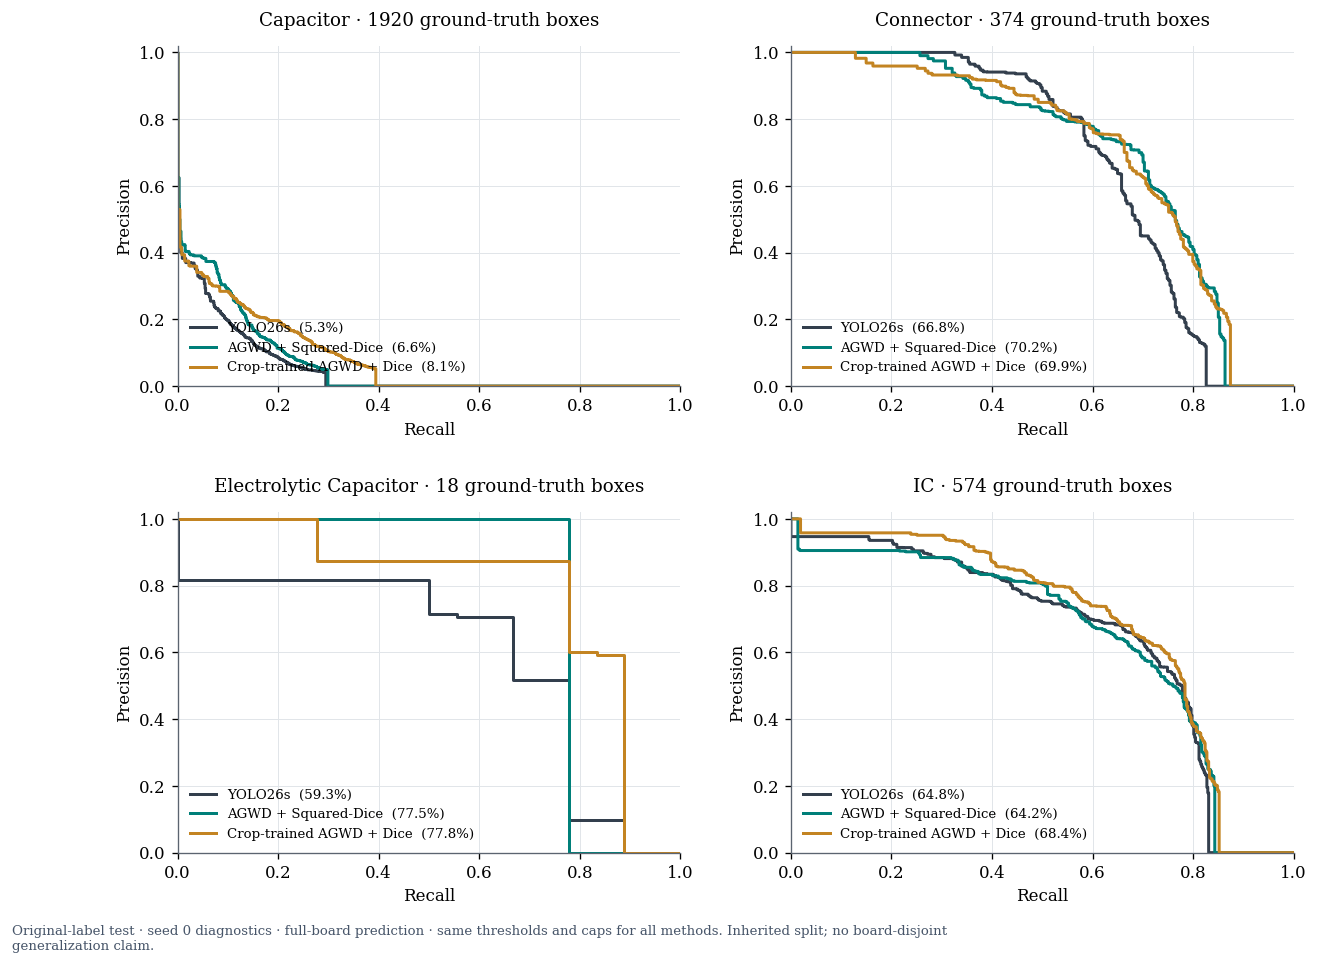

**Caption.** Seed-0 test PR precision envelopes from frozen common-profile predictions, using the pinned scorer's class-aware IoU matching and AP101 endpoint convention. Parenthesized values are this seed's class AP50, independently reproduced against saved metrics. These curves are not three-seed means.

In [6]:
fig,axes=plt.subplots(2,2,figsize=(12,8.2))
show=["yolo26s","yolo26s_agwd_sdice","yolo26s_crop_specialist"]
curve_rows=[]
for c,ax in enumerate(axes.ravel()):
    for m in show:
        a=CURVES[m][c]
        ax.plot(a["envelope_recall"],a["envelope_precision"],lw=1.8,color=COLORS[m],
                label=f'{LABELS[m]}  ({a["ap50"]*100:.1f}%)')
        curve_rows.extend(dict(model=m,component=a["component"],recall=float(r),precision=float(p))
                          for r,p in zip(a["recall"],a["precision"]))
    ax.set(xlim=(0,1),ylim=(0,1.02),xlabel="Recall",ylabel="Precision",
           title=f'{CLASSES[c]} · {CURVES[show[0]][c]["targets"]} ground-truth boxes')
    ax.grid(lw=.6);ax.legend(fontsize=8,loc="lower left")
export_table(pd.DataFrame(curve_rows),"seed0_pr_observations")
fig.subplots_adjust(hspace=.37,wspace=.22,bottom=.11,top=.93)
save_figure(fig,"05_precision_recall","Class-specific precision–recall curves",
    "Seed-0 test PR precision envelopes from frozen common-profile predictions, using the pinned scorer's "
    "class-aware IoU matching and AP101 endpoint convention. Parenthesized values are this seed's class AP50, "
    "independently reproduced against saved metrics. These curves are not three-seed means.",
    "Original-label test · seed 0 diagnostics · full-board prediction · same thresholds and caps for all methods.")

## 6. Confusion matrices with a declared matching rule
A class-agnostic spatial match exposes classification errors. This is a diagnostic, distinct from class-aware AP matching.

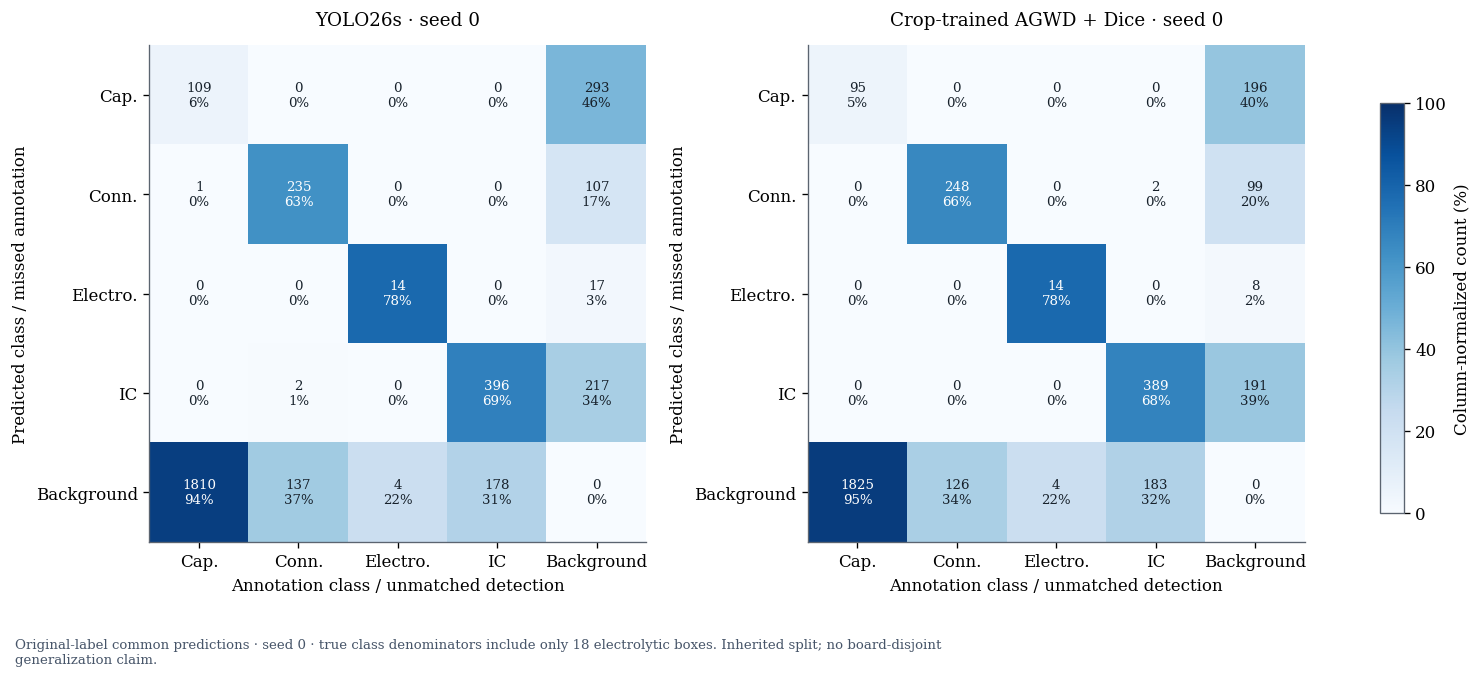

**Caption.** Greedy one-to-one class-agnostic IoU matching at IoU 0.50 and confidence 0.25. Rows denote predicted classes; columns denote annotation classes. Background row counts missed annotations; background column counts unmatched detections. Each column is normalized separately, so the background column is an FP composition, not recall. Raw counts are exported. This matrix is not the class-aware operating-metric matcher.

In [7]:
fig,axes=plt.subplots(1,2,figsize=(12.5,6))
names=["Cap.","Conn.","Electro.","IC","Background"]
for ax,m in zip(axes,["yolo26s","yolo26s_crop_specialist"]):
    matrix=confusion(GT,PRED[m]);den=matrix.sum(axis=0,keepdims=True)
    norm=100*np.divide(matrix,den,out=np.zeros_like(matrix,dtype=float),where=den>0)
    im=ax.imshow(norm,cmap="Blues",vmin=0,vmax=100)
    for i in range(5):
        for j in range(5):
            ax.text(j,i,f"{matrix[i,j]}\n{norm[i,j]:.0f}%",ha="center",va="center",fontsize=8,
                    color="white" if norm[i,j]>55 else "#17212b")
    ax.set(xticks=range(5),xticklabels=names,yticks=range(5),yticklabels=names,
           xlabel="Annotation class / unmatched detection",ylabel="Predicted class / missed annotation",
           title=LABELS[m]+" · seed 0")
    export_table(pd.DataFrame(matrix,index=CLASSES+["Background"],columns=CLASSES+["Background"]),
                 "confusion_counts_"+m)
fig.subplots_adjust(left=.09,right=.88,wspace=.25,bottom=.18,top=.87)
cax=fig.add_axes([.92,.22,.016,.57])
fig.colorbar(im,cax=cax,label="Column-normalized count (%)")
save_figure(fig,"06_confusion_matrices","Diagnostic confusion matrices",
    "Greedy one-to-one class-agnostic IoU matching at IoU 0.50 and confidence 0.25. Rows denote predicted classes; "
    "columns denote annotation classes. Background row counts missed annotations; background column counts unmatched "
    "detections. Each column is normalized separately, so the background column is an FP composition, not recall. "
    "Raw counts are exported. This matrix is not the class-aware operating-metric matcher.",
    "Original-label common predictions · seed 0 · true class denominators include only 18 electrolytic boxes.")

## 7. Detection comparisons and magnified details
Images and regions are selected by filename and annotation density, not by which method looks better.

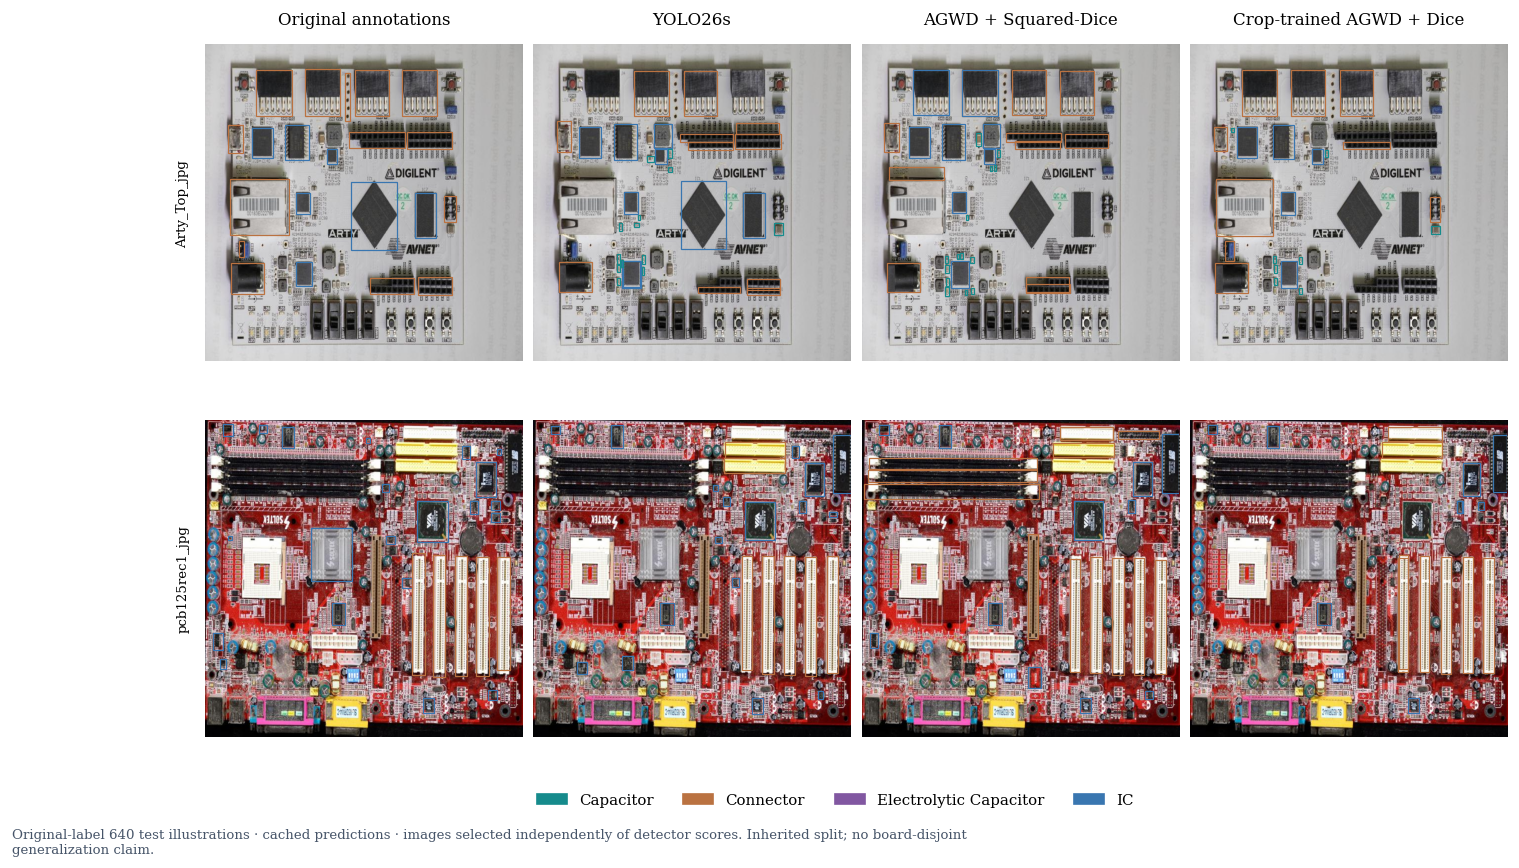

**Caption.** Two predeclared filename groups (Arty_Top and pcb125rec1), using the first export in frozen record order. Columns show original annotations and seed-0 predictions; only predictions with confidence at least 0.25 are displayed. Colors encode class, not correctness. Same image, crop and display threshold are used in every column. Unannotated detections are not automatically false positives because source labels may be incomplete.

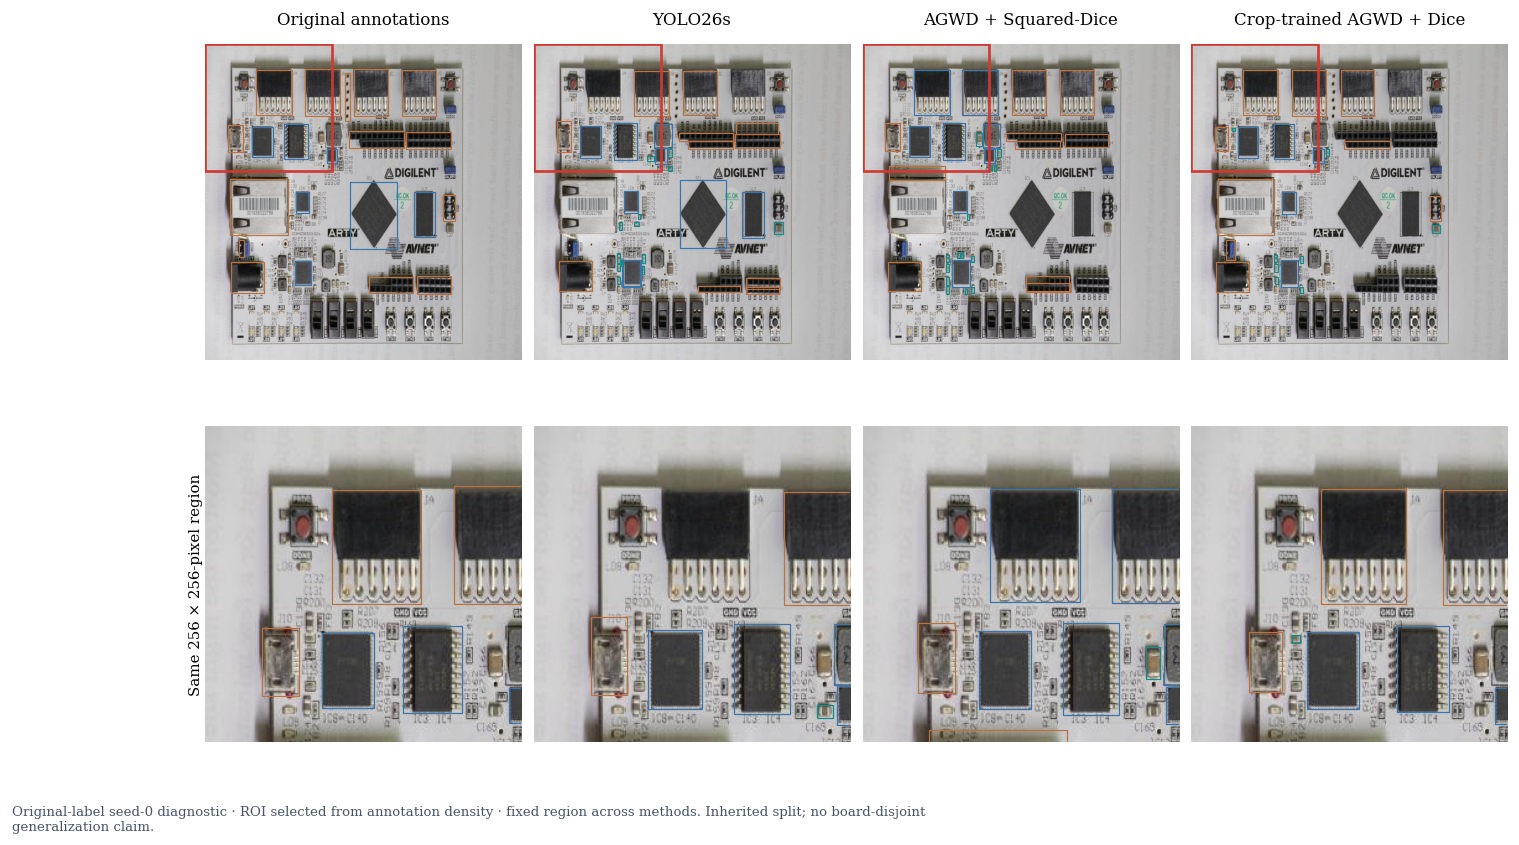

**Caption.** The same Arty_Top export as Figure 7, with ROI (0, 0, 256, 256). The region maximizes annotated capacitor centers over a fixed 256-pixel window grid; detector performance is not used for selection. Red outlines indicate the shared ROI. Enlarged display does not add image resolution. Prediction confidence is at least 0.25; boxes are cached seed-0 outputs rather than manually redrawn detections.

In [8]:
def draw_boxes(ax,image,boxes,classes,confidence=None,roi=None):
    ax.imshow(image);ax.axis("off")
    for k,(b,c) in enumerate(zip(boxes,classes)):
        if confidence is not None and confidence[k]<.25:continue
        x1,y1,x2,y2=b
        ax.add_patch(Rectangle((x1,y1),x2-x1,y2-y1,fill=False,edgecolor=CLASS_COLORS[int(c)],lw=.75))
    if roi is not None:
        x1,y1,x2,y2=roi
        ax.add_patch(Rectangle((x1,y1),x2-x1,y2-y1,fill=False,edgecolor="#d03932",lw=1.6))
def first_named(prefix):return next(i for i,g in enumerate(GT) if g["record"]["name"].startswith(prefix))
chosen=[first_named("Arty_Top"),first_named("pcb125rec1")]
comparison=[None,"yolo26s","yolo26s_agwd_sdice","yolo26s_crop_specialist"]
fig,axes=plt.subplots(2,4,figsize=(14,7.5))
for row,i in enumerate(chosen):
    g=GT[i];image=Image.open(g["image"]).convert("RGB")
    for col,m in enumerate(comparison):
        if m is None:draw_boxes(axes[row,col],image,g["boxes"],g["cls"])
        else:
            p=PRED[m][i];draw_boxes(axes[row,col],image,p[:,:4],p[:,5],p[:,4])
        if row==0:axes[row,col].set_title("Original annotations" if m is None else LABELS[m],fontsize=10)
    axes[row,0].text(-.05,.5,g["record"]["name"].split(".rf.")[0],rotation=90,
                    transform=axes[row,0].transAxes,ha="right",va="center",fontsize=8)
fig.legend(handles=[Patch(color=c,label=n) for c,n in zip(CLASS_COLORS,CLASSES)],
           loc="lower center",bbox_to_anchor=(.5,.047),ncol=4,fontsize=9)
fig.subplots_adjust(wspace=.035,hspace=.12,bottom=.13,top=.92)
save_figure(fig,"07_detection_comparison","Full-board detection comparisons",
    "Two predeclared filename groups (Arty_Top and pcb125rec1), using the first export in frozen record order. "
    "Columns show original annotations and seed-0 predictions; only predictions with confidence at least 0.25 "
    "are displayed. Colors encode class, not correctness. Same image, crop and display threshold are used in every "
    "column. Unannotated detections are not automatically false positives because source labels may be incomplete.",
    "Original-label 640 test illustrations · cached predictions · images selected independently of detector scores.")

i=chosen[0];g=GT[i];image=Image.open(g["image"]).convert("RGB")
windows=[(x,y,x+256,y+256) for y in [0,128,256,384] for x in [0,128,256,384]]
centers=(g["boxes"][:,:2]+g["boxes"][:,2:])/2
def density(r):
    x1,y1,x2,y2=r
    return int(((g["cls"]==0)&(centers[:,0]>=x1)&(centers[:,0]<x2)&
               (centers[:,1]>=y1)&(centers[:,1]<y2)).sum())
roi=max(windows,key=density)
fig,axes=plt.subplots(2,4,figsize=(14,7.3))
for col,m in enumerate(comparison):
    if m is None:b,c,conf=g["boxes"],g["cls"],None
    else:p=PRED[m][i];b,c,conf=p[:,:4],p[:,5],p[:,4]
    draw_boxes(axes[0,col],image,b,c,conf,roi)
    draw_boxes(axes[1,col],image,b,c,conf)
    axes[1,col].set_xlim(roi[0],roi[2]);axes[1,col].set_ylim(roi[3],roi[1])
    axes[0,col].set_title("Original annotations" if m is None else LABELS[m],fontsize=10)
axes[1,0].text(-.05,.5,"Same 256 × 256-pixel region",rotation=90,va="center",
               transform=axes[1,0].transAxes,fontsize=9)
fig.subplots_adjust(wspace=.04,hspace=.08,bottom=.09,top=.93)
save_figure(fig,"08_small_component_zoom","Small-component comparison with fixed zoom",
    f"The same Arty_Top export as Figure 7, with ROI {roi}. The region maximizes annotated capacitor centers over "
    "a fixed 256-pixel window grid; detector performance is not used for selection. Red outlines indicate the shared "
    "ROI. Enlarged display does not add image resolution. Prediction confidence is at least 0.25; boxes are cached "
    "seed-0 outputs rather than manually redrawn detections.",
    "Original-label seed-0 diagnostic · ROI selected from annotation density · fixed region across methods.")

## 8. Training dynamics and inference cost
Training-time validation uses a different batching/rectangular setup from the common final audit. Curve endpoints are not substituted for final test metrics.

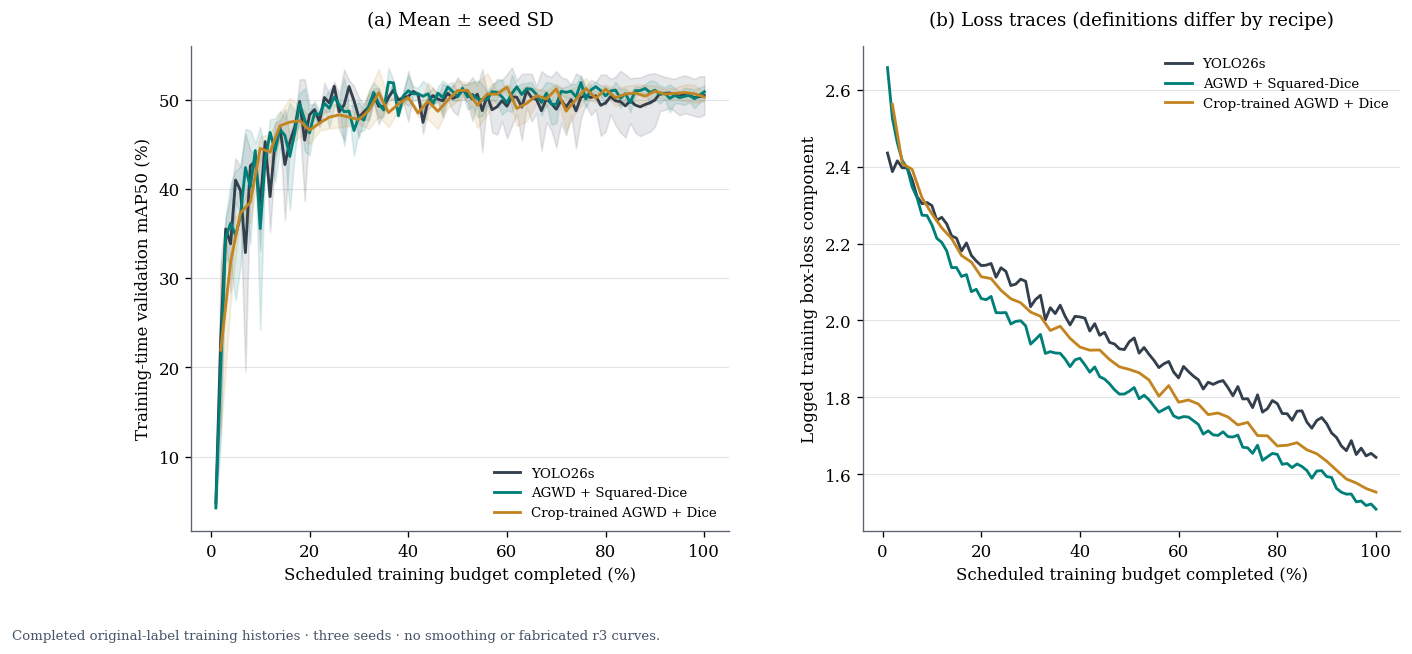

**Caption.** Mean validation mAP50 and box-loss traces from the actual completed CSV logs, seeds 0/1/2. Full-board methods use 100 epochs and mixed-crop training 50; the x-axis is normalized scheduled budget, not an equal epoch count. Training-time rectangular/batched validation differs from the common square batch-one final evaluator. Different box-loss definitions mean their absolute loss magnitudes are not directly comparable.

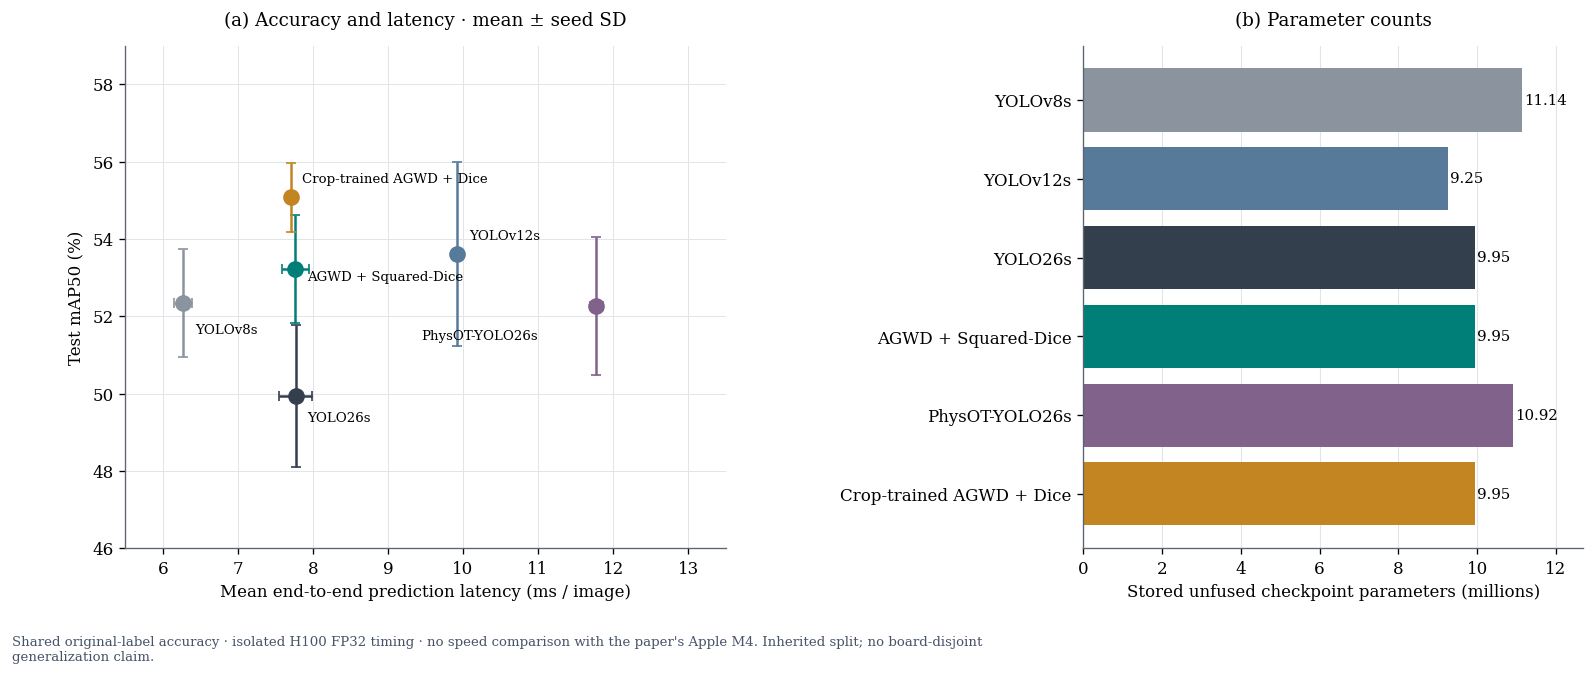

**Caption.** The same 18 checkpoints used in the primary accuracy comparison were independently benchmarked on an isolated NVIDIA H100 80GB, FP32, square 640 and batch one. Thirty warmups and 100 timed predictions per checkpoint; latency includes preprocessing, detector and postprocessing, excluding disk decoding/model loading. Error bars are SD across the three checkpoint means. Counts are stored unfused parameters, not FLOPs.

In [9]:
fig,axes=plt.subplots(1,2,figsize=(13,5.7))
for method in ["yolo26s","yolo26s_agwd_sdice","yolo26s_crop_specialist"]:
    histories=[]
    for entry in T["manifest"]["checkpoints"]:
        if entry["model"]==method:
            path=ROOT/"runs"/entry["job"]/"pcb-filtered/results.csv"
            history=pd.read_csv(path);history.columns=history.columns.str.strip()
            assert len(history)==(50 if method=="yolo26s_crop_specialist" else 100)
            histories.append(history)
    # Equal sample budgets: horizontal coordinate is fraction of the scheduled training budget.
    h=np.stack([d["metrics/mAP50(B)"].values for d in histories])
    progress=np.arange(1,h.shape[1]+1)/h.shape[1]*100
    axes[0].plot(progress,h.mean(0)*100,label=LABELS[method],color=COLORS[method],lw=1.7)
    axes[0].fill_between(progress,(h.mean(0)-h.std(0,ddof=1))*100,
                         (h.mean(0)+h.std(0,ddof=1))*100,color=COLORS[method],alpha=.12)
    loss=np.stack([d["train/box_loss"].values for d in histories])
    axes[1].plot(progress,loss.mean(0),label=LABELS[method],color=COLORS[method],lw=1.7)
axes[0].set(xlabel="Scheduled training budget completed (%)",ylabel="Training-time validation mAP50 (%)",title="(a) Mean ± seed SD")
axes[1].set(xlabel="Scheduled training budget completed (%)",ylabel="Logged training box-loss component",title="(b) Loss traces (definitions differ by recipe)")
for ax in axes:style(ax);ax.legend(fontsize=8)
fig.subplots_adjust(bottom=.17,wspace=.25,top=.88)
save_figure(fig,"09_training_dynamics","Completed training dynamics",
    "Mean validation mAP50 and box-loss traces from the actual completed CSV logs, seeds 0/1/2. Full-board methods "
    "use 100 epochs and mixed-crop training 50; the x-axis is normalized scheduled budget, not an equal epoch count. "
    "Training-time rectangular/batched validation differs from the common square batch-one final evaluator. "
    "Different box-loss definitions mean their absolute loss magnitudes are not directly comparable.",
    "Completed original-label training histories · three seeds · no smoothing or fabricated r3 curves.")

fig,axes=plt.subplots(1,2,figsize=(13.5,5.9),gridspec_kw={"width_ratios":[1.2,1]})
for method in METHODS:
    r=P.loc[method]
    axes[0].errorbar(r.latency_ms_mean,r.mAP50_mean*100,xerr=r.latency_ms_std,
        yerr=r.mAP50_std*100,fmt="o",markersize=9,color=COLORS[method],capsize=3)
    offsets={"yolov8s":(7,-18),"yolov12s":(7,9),"yolo26s":(7,-15),
             "yolo26s_agwd_sdice":(7,-7),"physot_yolo26s":(-105,-20),
             "yolo26s_crop_specialist":(7,9)}
    axes[0].annotate(LABELS[method],(r.latency_ms_mean,r.mAP50_mean*100),
                     xytext=offsets[method],textcoords="offset points",fontsize=8)
axes[0].set(xlabel="Mean end-to-end prediction latency (ms / image)",ylabel="Test mAP50 (%)",
            title="(a) Accuracy and latency · mean ± seed SD",xlim=(5.5,13.5),ylim=(46,59))
axes[0].grid(lw=.6)
axes[1].barh(range(6),P.parameters/1e6,color=[COLORS[m] for m in METHODS])
axes[1].set(yticks=range(6),yticklabels=[LABELS[m] for m in METHODS],
            xlabel="Stored unfused checkpoint parameters (millions)",title="(b) Parameter counts")
axes[1].invert_yaxis();style(axes[1],"x")
for i,v in enumerate(P.parameters/1e6):axes[1].text(v+.05,i,f"{v:.2f}",va="center",fontsize=9)
axes[1].set_xlim(0,12.7)
fig.subplots_adjust(left=.08,right=.98,bottom=.17,top=.88,wspace=.65)
save_figure(fig,"10_accuracy_speed_parameters","Accuracy, latency and model size",
    "The same 18 checkpoints used in the primary accuracy comparison were independently benchmarked on an isolated "
    "NVIDIA H100 80GB, FP32, square 640 and batch one. Thirty warmups and 100 timed predictions per checkpoint; "
    "latency includes preprocessing, detector and postprocessing, excluding disk decoding/model loading. "
    "Error bars are SD across the three checkpoint means. Counts are stored unfused parameters, not FLOPs.",
    "Shared original-label accuracy · isolated H100 FP32 timing · no speed comparison with the paper's Apple M4.")

## 9. Historical native-resolution ensembles and controlled loss comparison
These are separate exploratory studies. They are not r3 results or independent unseen-holdout evidence.

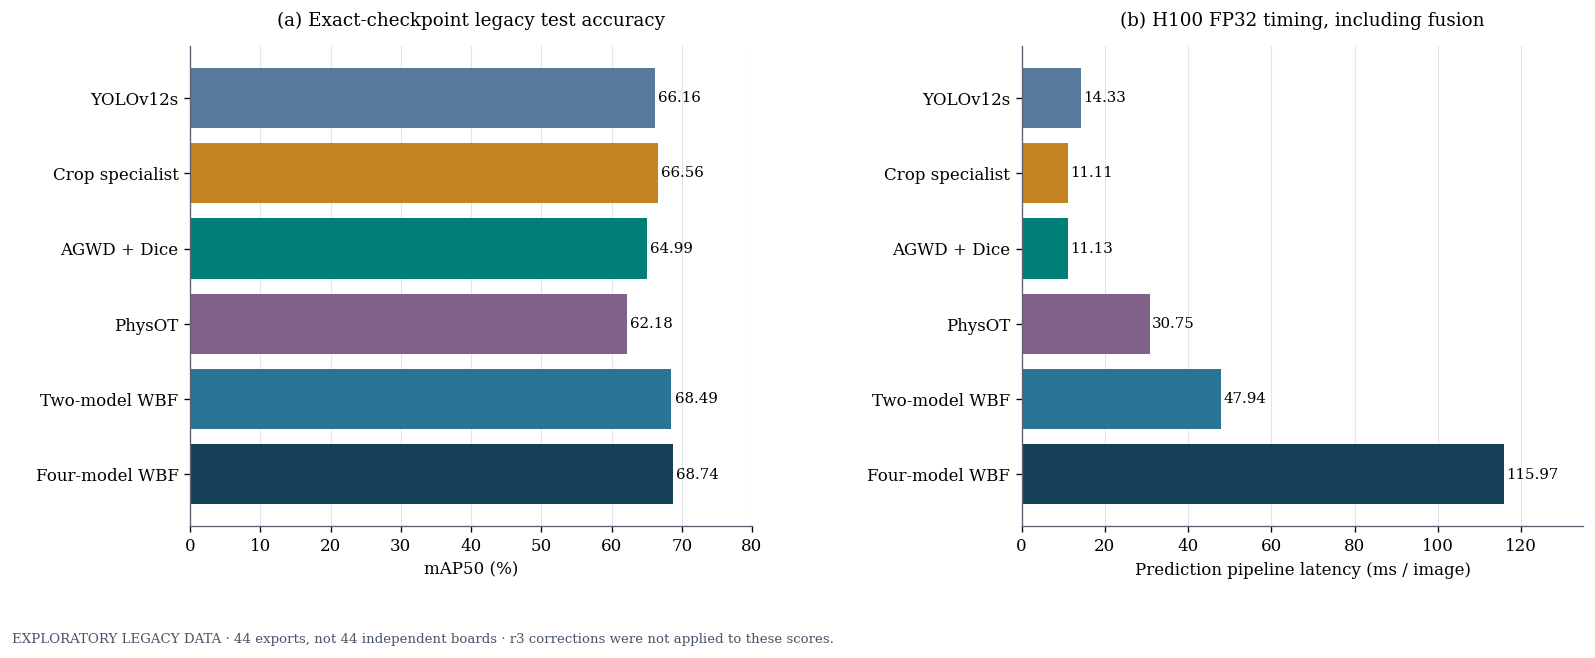

**Caption.** Four fixed checkpoints and two fixed WBF combinations on the original 44-export legacy test split, square 1280 and FP32. WBF weights are 1.3/1.2 and 1.3/1.2/1.1/1.0, merge IoU 0.50. No new ensemble tuning occurs. These are selected checkpoints with different training recipes. Later review confirmed cross-split photograph overlap and label defects; the scores are exploratory and not certified generalization results.

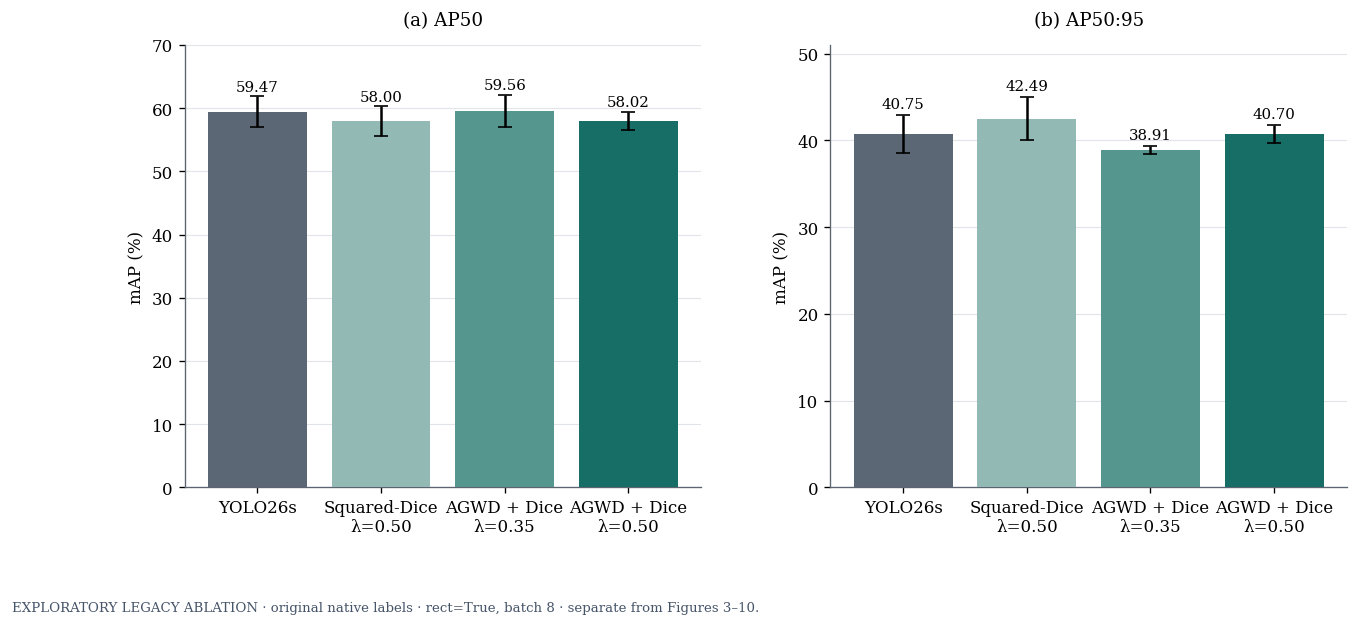

**Caption.** Related YOLO26s loss recipes from the completed no-extra-online-augmentation native study, mean ± sample SD over seeds 0/1/2. Squared-Dice smoothing is 0.01. This study used rectangular batch-8 FP32 evaluation, not the selected-champion square batch-one audit. All 21 results, including seven methods and negative comparisons, remain in the source summary; this panel selects the four related YOLO26s loss recipes by architecture rather than score. Shared legacy split/annotation limitations remain.

In [10]:
N=T["native"]
fig,axes=plt.subplots(1,2,figsize=(13.5,5.8))
names=["YOLOv12s","Crop specialist","AGWD + Dice","PhysOT","Two-model WBF","Four-model WBF"]
colors=["#577a9b","#c38422","#007f79","#80628b","#2a7495","#163f58"]
for ax,values,label,title in [
    (axes[0],N.mAP50*100,"mAP50 (%)","(a) Exact-checkpoint legacy test accuracy"),
    (axes[1],N.latency_ms,"Prediction pipeline latency (ms / image)","(b) H100 FP32 timing, including fusion")]:
    ax.barh(range(6),values,color=colors)
    ax.set(yticks=range(6),yticklabels=names,xlabel=label,title=title)
    ax.invert_yaxis();style(ax,"x")
    for i,v in enumerate(values):ax.text(v+.5,i,f"{v:.2f}",va="center",fontsize=9)
axes[0].set_xlim(0,80);axes[1].set_xlim(0,135)
fig.subplots_adjust(left=.12,right=.98,wspace=.48,bottom=.18,top=.87)
save_figure(fig,"11_legacy_ensembles","Exploratory native-resolution ensemble audit",
    "Four fixed checkpoints and two fixed WBF combinations on the original 44-export legacy test split, square "
    "1280 and FP32. WBF weights are 1.3/1.2 and 1.3/1.2/1.1/1.0, merge IoU 0.50. No new ensemble tuning occurs. "
    "These are selected checkpoints with different training recipes. Later review confirmed cross-split photograph "
    "overlap and label defects; the scores are exploratory and not certified generalization results.",
    "EXPLORATORY LEGACY DATA · 44 exports, not 44 independent boards · r3 corrections were not applied to these scores.")

selection=["yolo26s","yolo26s_sdice","yolo26s_agwd_sdice_l035","yolo26s_agwd_sdice"]
A=T["ablation"].loc[selection]
fig,axes=plt.subplots(1,2,figsize=(12.5,5.5))
labels=["YOLO26s","Squared-Dice\nλ=0.50","AGWD + Dice\nλ=0.35","AGWD + Dice\nλ=0.50"]
for ax,metric,title in zip(axes,["mAP50","mAP50_95"],["(a) AP50","(b) AP50:95"]):
    vals=A[metric+"_mean"];err=A[metric+"_std"]
    ax.bar(range(4),vals,yerr=err,capsize=4,color=["#5c6775","#93b9b4","#55978f","#176e67"],zorder=3)
    for i,v in enumerate(vals):ax.text(i,v+err.iloc[i]+.8,f"{v:.2f}",ha="center",fontsize=9)
    ax.set(xticks=range(4),xticklabels=labels,ylabel="mAP (%)",title=title,ylim=(0,70 if metric=="mAP50" else 51));style(ax)
fig.subplots_adjust(bottom=.20,top=.87,wspace=.25)
save_figure(fig,"12_legacy_loss_comparison","Historical three-seed loss comparison",
    "Related YOLO26s loss recipes from the completed no-extra-online-augmentation native study, "
    "mean ± sample SD over seeds 0/1/2. Squared-Dice smoothing is 0.01. "
    "This study used rectangular batch-8 FP32 evaluation, not the selected-champion square batch-one audit. "
    "All 21 results, including seven methods and negative comparisons, remain in the source summary; "
    "this panel selects the four related YOLO26s loss recipes by architecture rather than score. "
    "Shared legacy split/annotation limitations remain.",
    "EXPLORATORY LEGACY ABLATION · original native labels · rect=True, batch 8 · separate from Figures 3–10.")

## 10. Actual annotation corrections: data-quality evidence, not new accuracy

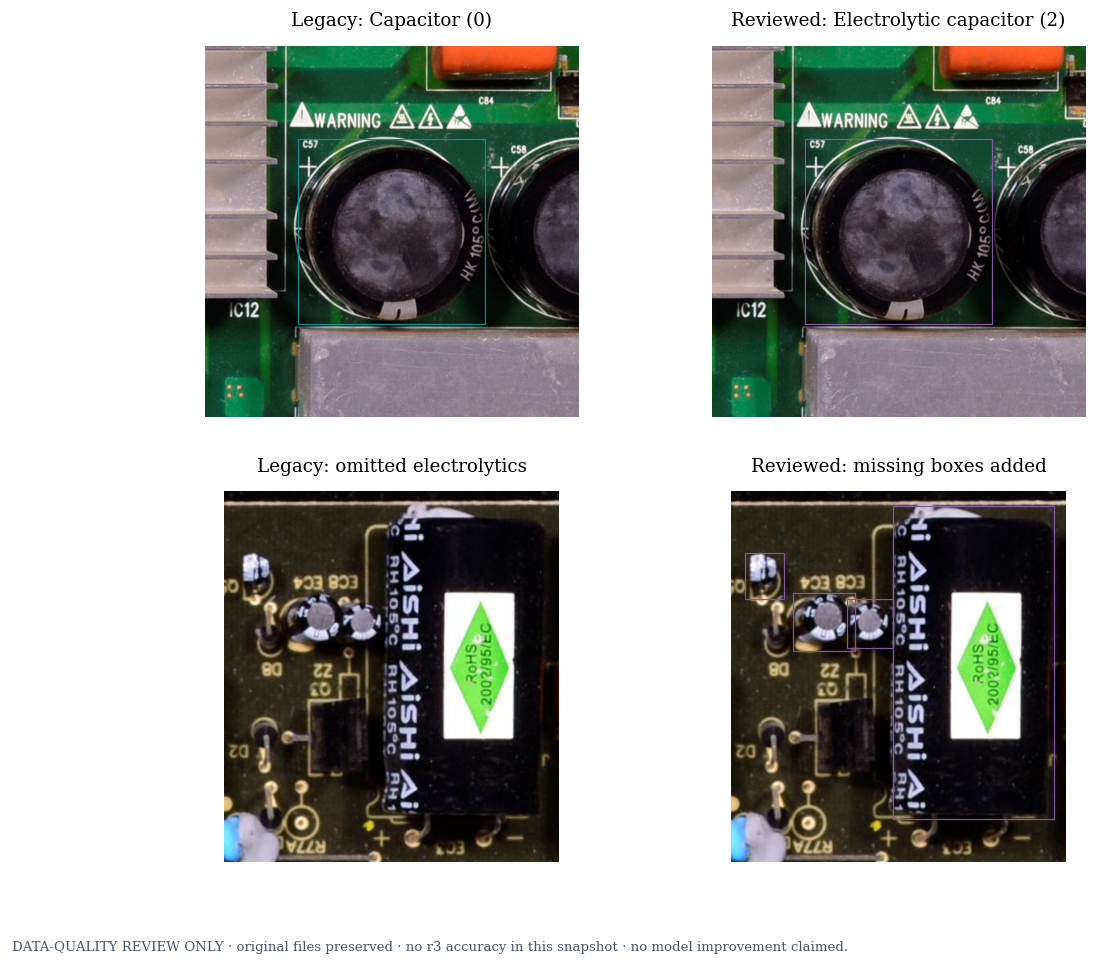

**Caption.** Top: an existing class-0 annotation changed to class 2, retaining its coordinates. Bottom: four clearly identifiable capacitors that lacked source boxes. These are traced label edits, not model predictions. The full review records 1,758 class changes, 95 additions and 25 deletions across 212 exports. Those totals include transformed/resized variants, not independent objects. R3 component-level review is incomplete; no new training accuracy is inferred from this illustration.

In [11]:
review=ROOT/"data_review/native1280_v2_20261106"
source=load(review/"audit/inventory.json")
records={r["id"]:r for r in source["records"]}
patches=load(review/"patches_final_r3.json")
# Deterministic example: largest reclassified capacitor box among test exports.
changes=[p for p in patches if p["action"]=="replace" and p["id"].startswith("test/")]
def patch_area(p):
    r=records[p["id"]];b=next(b for b in r["boxes"] if b["line"]==p["line"])
    return b["xywh"][2]*b["xywh"][3]
p=max(changes,key=patch_area);r=records[p["id"]];b=next(b for b in r["boxes"] if b["line"]==p["line"])
xywh=np.array(b["xywh"])*np.array([r["width"],r["height"],r["width"],r["height"]])
xyxy=np.r_[xywh[:2]-xywh[2:]/2,xywh[:2]+xywh[2:]/2]
pad=max(xywh[2:])*.5;roi=(max(0,xyxy[0]-pad),max(0,xyxy[1]-pad),min(r["width"],xyxy[2]+pad),min(r["height"],xyxy[3]+pad))
def native_review_image(record):
    split,name=record["id"].split("/",1)
    candidates=[review/"source"/split/"images"/name,
                ROOT/"datasets/pcb-native-res-cleaned-1280"/split/"images"/name,
                Path(record["image"])]
    return next(path for path in candidates if path.is_file() and sha(path)==record["image_sha256"])
example_image=native_review_image(r)
assert p["replacement"].split()[0]=="2"
image=Image.open(example_image).convert("RGB")
fig,axes=plt.subplots(2,2,figsize=(10.5,8.2))
for ax,c,label in zip(axes[0],[0,2],["Legacy: Capacitor (0)","Reviewed: Electrolytic capacitor (2)"]):
    draw_boxes(ax,image,np.array([xyxy]),np.array([c]))
    ax.set_xlim(roi[0],roi[2]);ax.set_ylim(roi[3],roi[1]);ax.set_title(label)
miss=next(r for r in source["records"] if r["id"]=="train/pcb149rec1_jpg.rf.326922824f63217a6e1021689887440a.jpg")
image=Image.open(native_review_image(miss)).convert("RGB");roi=(735,0,1150,460)
added=[a for a in patches if a["id"]==miss["id"] and a["action"]=="add"]
new_boxes=[]
for a in added:
    _,x,y,w,h=map(float,a["replacement"].split());W,H=miss["width"],miss["height"]
    new_boxes.append([(x-w/2)*W,(y-h/2)*H,(x+w/2)*W,(y+h/2)*H])
for ax,after in zip(axes[1],[False,True]):
    draw_boxes(ax,image,np.array(new_boxes).reshape(-1,4) if after else np.empty((0,4)),
               np.full(len(new_boxes),2) if after else np.empty(0))
    ax.set_xlim(roi[0],roi[2]);ax.set_ylim(roi[3],roi[1])
    ax.set_title("Reviewed: missing boxes added" if after else "Legacy: omitted electrolytics")
fig.subplots_adjust(top=.93,bottom=.10,wspace=.08,hspace=.20)
save_figure(fig,"13_annotation_corrections","Traced annotation correction examples",
    "Top: an existing class-0 annotation changed to class 2, retaining its coordinates. Bottom: four clearly "
    "identifiable capacitors that lacked source boxes. These are traced label edits, not model predictions. "
    "The full review records 1,758 class changes, 95 additions and 25 deletions across 212 exports. "
    "Those totals include transformed/resized variants, not independent objects. R3 component-level review "
    "is incomplete; no new training accuracy is inferred from this illustration.",
    "DATA-QUALITY REVIEW ONLY · original files preserved · no r3 accuracy in this snapshot · no model improvement claimed.")

## 11. Literature context: keep published and reproduced-control scores distinct

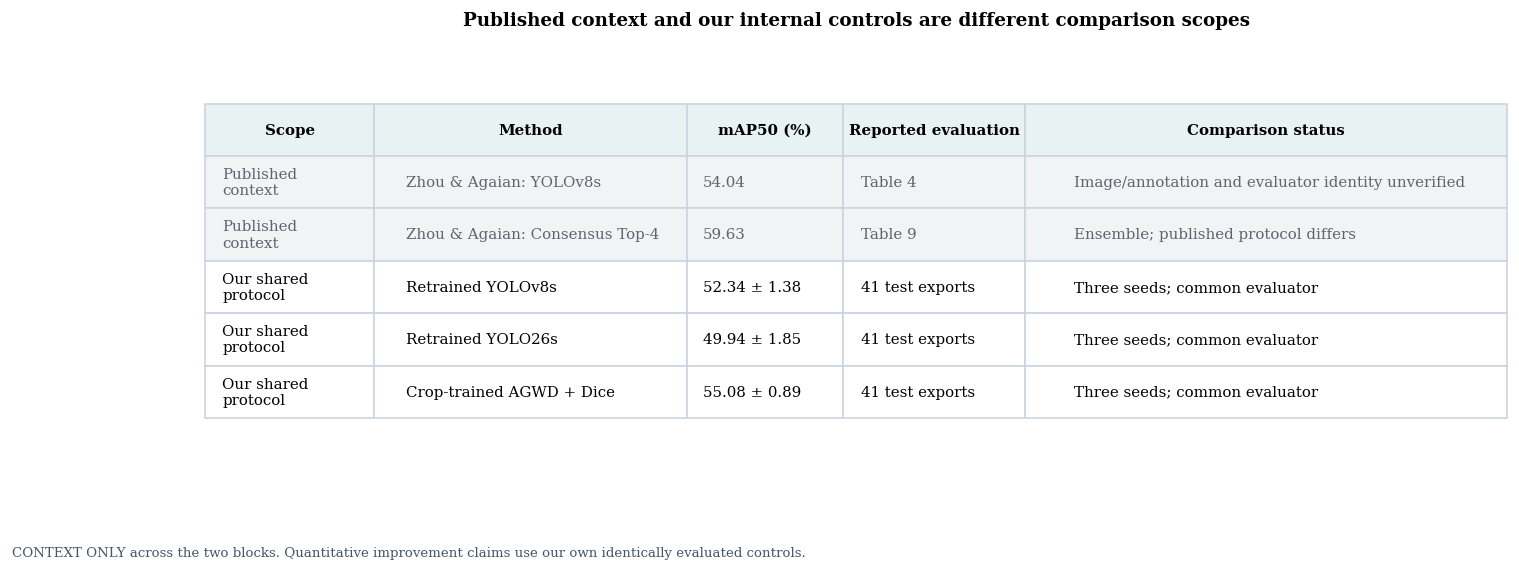

**Caption.** Published values are author-reported from Zhou and Agaian, Information 2026, 17, 322, doi:10.3390/info17040322, Tables 4 and 9. Our results use the available original-label RF100 exports and a frozen shared evaluator. Exact author image/annotation identities and table-specific evaluation settings remain unresolved. No cross-block improvement, ranking or speedup claim is justified.

In [12]:
literature=pd.DataFrame([
    ["Published\ncontext","Zhou & Agaian: YOLOv8s","54.04","Table 4","Image/annotation and evaluator identity unverified"],
    ["Published\ncontext","Zhou & Agaian: Consensus Top-4","59.63","Table 9","Ensemble; published protocol differs"],
    ["Our shared\nprotocol","Retrained YOLOv8s",f"{P.loc['yolov8s','mAP50_mean']*100:.2f} ± {P.loc['yolov8s','mAP50_std']*100:.2f}","41 test exports","Three seeds; common evaluator"],
    ["Our shared\nprotocol","Retrained YOLO26s",f"{P.loc['yolo26s','mAP50_mean']*100:.2f} ± {P.loc['yolo26s','mAP50_std']*100:.2f}","41 test exports","Three seeds; common evaluator"],
    ["Our shared\nprotocol","Crop-trained AGWD + Dice",f"{P.loc['yolo26s_crop_specialist','mAP50_mean']*100:.2f} ± {P.loc['yolo26s_crop_specialist','mAP50_std']*100:.2f}","41 test exports","Three seeds; common evaluator"],
],columns=["Scope","Method","mAP50 (%)","Reported evaluation","Comparison status"])
export_table(literature,"published_context_separated")
fig,ax=plt.subplots(figsize=(14,4.8));ax.axis("off")
table=ax.table(cellText=literature.values,colLabels=literature.columns,
    colWidths=[.13,.24,.12,.14,.37],loc="center",cellLoc="left",bbox=[0,.17,1,.70])
table.auto_set_font_size(False);table.set_fontsize(9)
for (i,j),cell in table.get_celld().items():
    cell.set_edgecolor("#cbd5e1")
    if i==0:cell.set_facecolor("#e9f2f2");cell.set_text_props(fontweight="bold")
    elif i<=2:cell.set_facecolor("#f2f3f4");cell.set_text_props(color="#5d6470")
ax.set_title("Published context and our internal controls are different comparison scopes",fontweight="bold")
fig.subplots_adjust(bottom=.12,top=.90)
save_figure(fig,"14_published_context","Published context with explicit comparability limits",
    "Published values are author-reported from Zhou and Agaian, Information 2026, 17, 322, "
    "doi:10.3390/info17040322, Tables 4 and 9. Our results use the available original-label RF100 exports "
    "and a frozen shared evaluator. Exact author image/annotation identities and table-specific evaluation "
    "settings remain unresolved. No cross-block improvement, ranking or speedup claim is justified.",
    "CONTEXT ONLY across the two blocks. Quantitative improvement claims use our own identically evaluated controls.")

## 12. Native champion and ensemble details
These tables preserve the exact audited checkpoints and the legacy-data limitations.

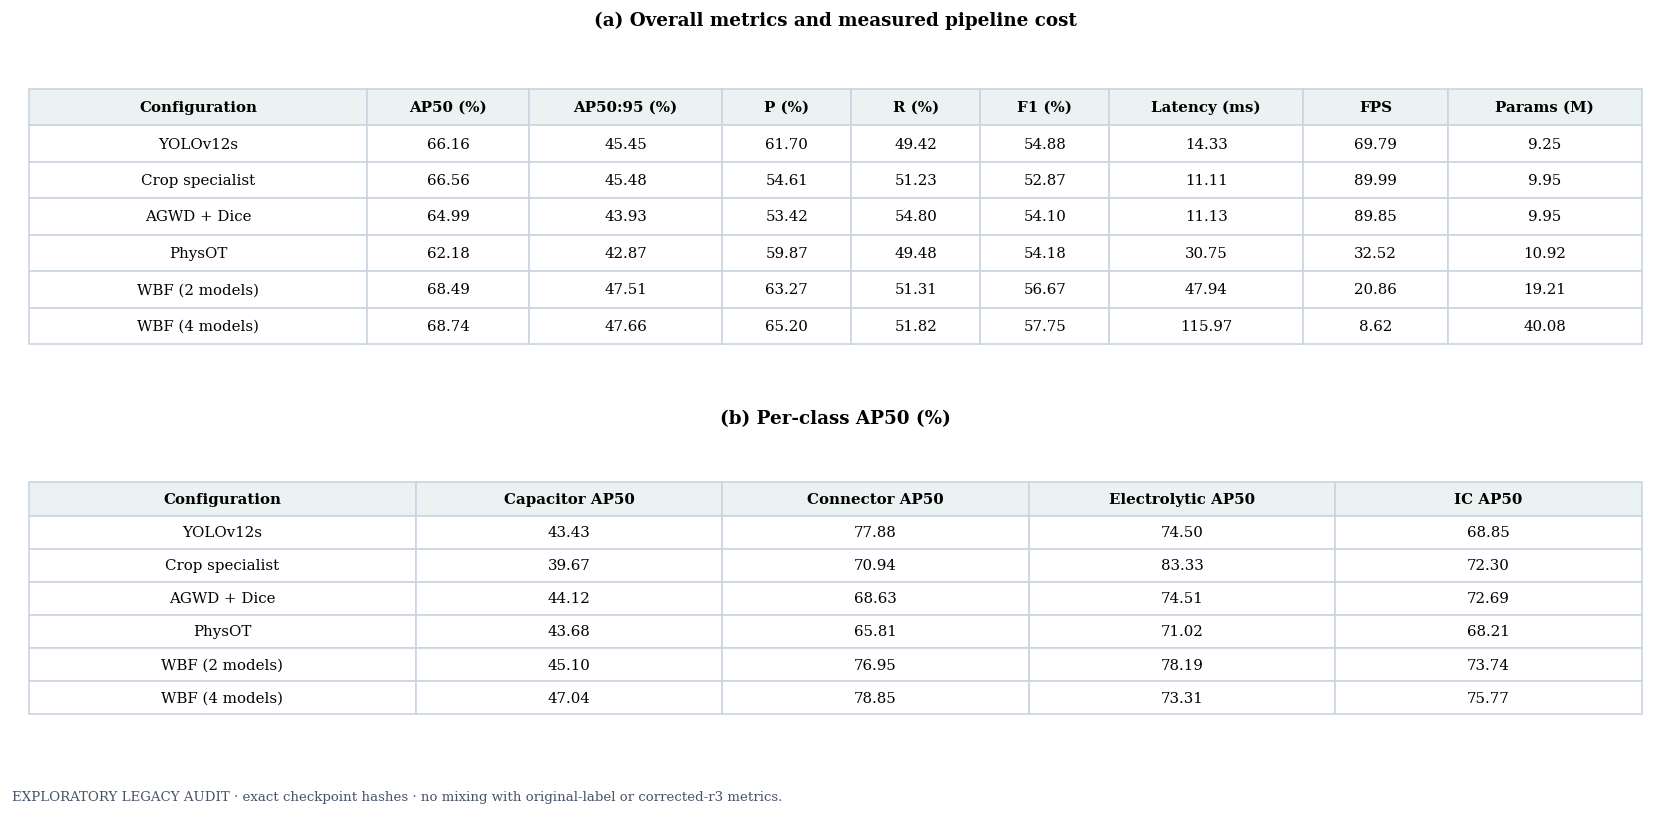

**Caption.** All six completed legacy configurations under the same square-1280 batch-one FP32 audit. P/R/F1 pool counts at confidence 0.25 and matching IoU 0.50; AP uses all saved predictions. Latency includes preprocessing, detector, postprocessing and WBF fusion; FPS is 1,000 divided by mean latency. Parameters sum the stored unfused member checkpoints. Class AP values include the legacy electrolytic category with only 18 annotations. Known cross-split photographs and labeling defects preclude a final independent-generalization claim.

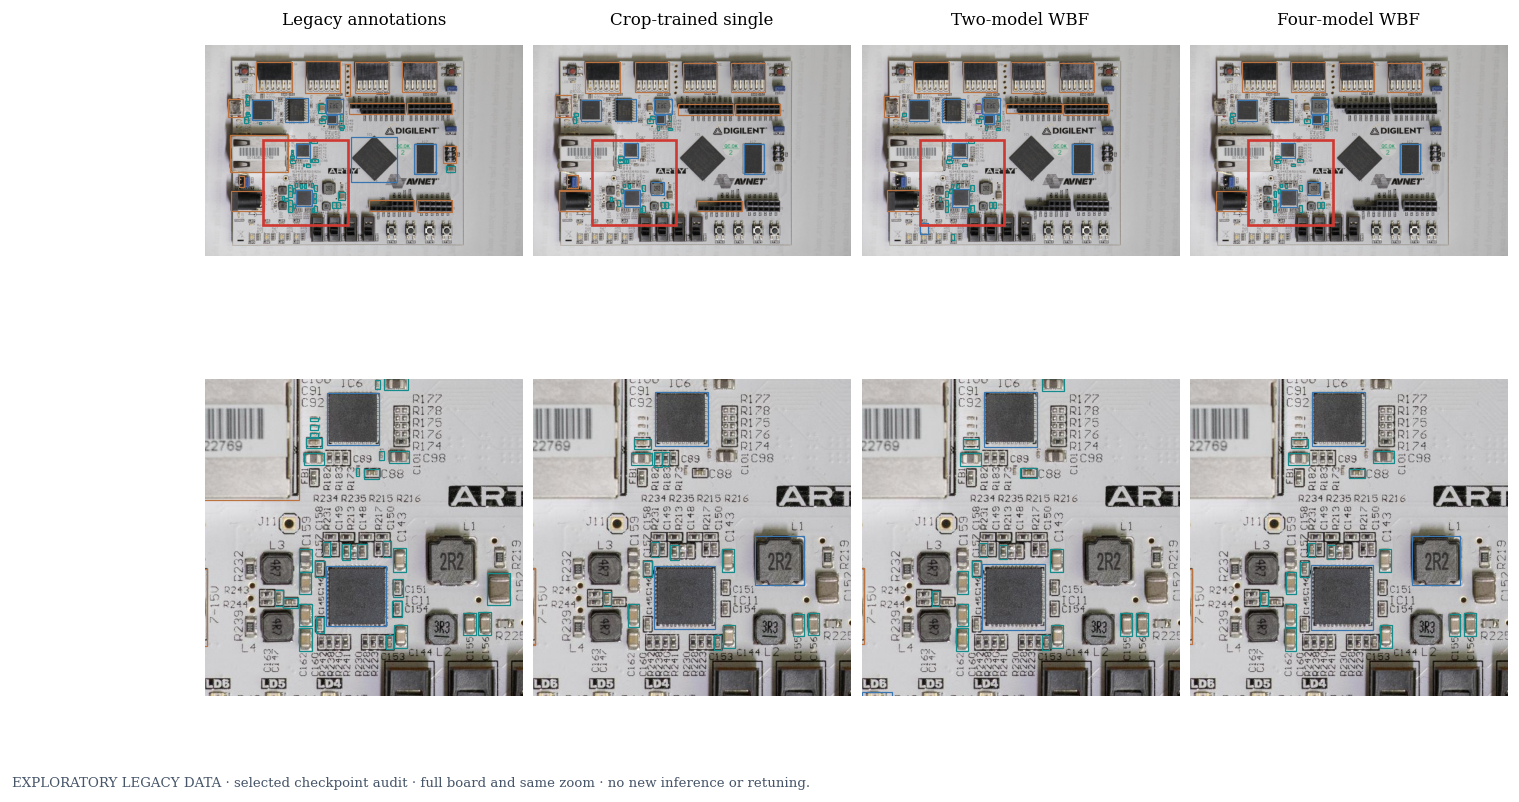

**Caption.** One predeclared Arty_Top legacy export and its annotation-density-selected zoom. Predictions are exactly the cached audit outputs, with confidence at least 0.25 for display. WBF confidence rescaling is preserved; equal numeric confidence does not imply identical score calibration across pipelines. Original image/label hashes and all three caches were checked, and their class AP50 and operating TP/FP counts independently reproduced. Colors denote class, not correctness. Native split overlap and annotation limitations remain.

In [13]:
N=T["native"]
compact=["YOLOv12s","Crop specialist","AGWD + Dice","PhysOT","WBF (2 models)","WBF (4 models)"]
top=[]
for label,(_,r) in zip(compact,N.iterrows()):
    top.append([label,*[f"{r[k]*100:.2f}" for k in ["mAP50","mAP50_95","precision","recall","f1"]],
                f"{r.latency_ms:.2f}",f"{r.fps:.2f}",f"{r.parameters/1e6:.2f}"])
bottom=[[label,*[f'{r["accuracy"]["per_class"][c]["ap50"]*100:.2f}' for c in CLASSES]]
        for label,r in zip(compact,T["native_raw"]["results"])]
fig,axes=plt.subplots(2,1,figsize=(14,7),gridspec_kw={"height_ratios":[1.1,1]})
for ax,values,headers,widths,title in [
    (axes[0],top,["Configuration","AP50 (%)","AP50:95 (%)","P (%)","R (%)","F1 (%)","Latency (ms)","FPS","Params (M)"],
     [.21,.10,.12,.08,.08,.08,.12,.09,.12],"(a) Overall metrics and measured pipeline cost"),
    (axes[1],bottom,["Configuration","Capacitor AP50","Connector AP50","Electrolytic AP50","IC AP50"],
     [.24,.19,.19,.19,.19],"(b) Per-class AP50 (%)")]:
    ax.axis("off");table=ax.table(cellText=values,colLabels=headers,colWidths=widths,
                                cellLoc="center",bbox=[0,.04,1,.82])
    table.auto_set_font_size(False);table.set_fontsize(9)
    for (i,j),cell in table.get_celld().items():
        cell.set_edgecolor("#cbd5e1")
        if i==0:cell.set_facecolor("#eaf2f2");cell.set_text_props(fontweight="bold")
    ax.set_title(title,fontweight="bold")
fig.subplots_adjust(left=.02,right=.98,top=.91,bottom=.10,hspace=.29)
save_figure(fig,"15_native_master_metrics","Exact native champion and ensemble metrics",
    "All six completed legacy configurations under the same square-1280 batch-one FP32 audit. "
    "P/R/F1 pool counts at confidence 0.25 and matching IoU 0.50; AP uses all saved predictions. "
    "Latency includes preprocessing, detector, postprocessing and WBF fusion; FPS is 1,000 divided by mean "
    "latency. Parameters sum the stored unfused member checkpoints. Class AP values include the legacy "
    "electrolytic category with only 18 annotations. Known cross-split photographs and labeling defects "
    "preclude a final independent-generalization claim.",
    "EXPLORATORY LEGACY AUDIT · exact checkpoint hashes · no mixing with original-label or corrected-r3 metrics.")

native_manifest=T["native_raw"]["manifest"]
native_records=native_manifest["records"]
cache=load(ROOT/NATIVE/"predictions/crop.json")
native_gt=[]
for rec,shape in zip(native_records,cache["shapes"]):
    candidates=[ROOT/"data_review/native1280_v2_20261106/source/test/images"/rec["name"],
                ROOT/"datasets/pcb-native-res-cleaned-1280/test/images"/rec["name"]]
    path=next(p for p in candidates if p.is_file() and sha(p)==rec["image_sha256"])
    label=path.parent.parent/"labels"/(path.stem+".txt")
    assert sha(label)==rec["label_sha256"]
    c,b=boxes_from_label(label,shape)
    native_gt.append(dict(image=path,cls=c,boxes=b,record=rec))
native_pred={}
for key in ["crop","ensemble2","ensemble4"]:
    path=ROOT/NATIVE/"predictions"/(key+".json");cached=load(path)
    assert cached["manifest_id"]==native_manifest["id"]
    assert cached["image_names"]==[r["name"] for r in native_records]
    native_pred[key]=[np.asarray(p,dtype=np.float32).reshape(-1,6) for p in cached["predictions"]]
    expected=next(r["accuracy"] for r in T["native_raw"]["results"] if r["id"]==key)
    curves_and_checks(native_gt,native_pred[key],expected)
    SOURCE_HASHES[str(path.relative_to(ROOT))]=sha(path)
chosen_native=next(i for i,g in enumerate(native_gt) if g["record"]["name"].startswith("Arty_Top"))
g=native_gt[chosen_native];image=Image.open(g["image"]).convert("RGB");W,H=image.size
centers=(g["boxes"][:,:2]+g["boxes"][:,2:])/2;size=int(min(W,H)*.4)
windows=[(x,y,x+size,y+size) for y in np.linspace(0,H-size,5).astype(int)
         for x in np.linspace(0,W-size,5).astype(int)]
def native_density(r):
    x1,y1,x2,y2=r
    return int(((g["cls"]==0)&(centers[:,0]>=x1)&(centers[:,0]<x2)&
                (centers[:,1]>=y1)&(centers[:,1]<y2)).sum())
roi=max(windows,key=native_density)
fig,axes=plt.subplots(2,4,figsize=(14,7.4))
for col,key in enumerate([None,"crop","ensemble2","ensemble4"]):
    if key is None:b,c,conf=g["boxes"],g["cls"],None
    else:p=native_pred[key][chosen_native];b,c,conf=p[:,:4],p[:,5],p[:,4]
    draw_boxes(axes[0,col],image,b,c,conf,roi)
    draw_boxes(axes[1,col],image,b,c,conf)
    axes[1,col].set_xlim(roi[0],roi[2]);axes[1,col].set_ylim(roi[3],roi[1])
    axes[0,col].set_title({None:"Legacy annotations","crop":"Crop-trained single",
                          "ensemble2":"Two-model WBF","ensemble4":"Four-model WBF"}[key],fontsize=10)
fig.subplots_adjust(wspace=.035,hspace=.08,top=.93,bottom=.09)
save_figure(fig,"16_native_ensemble_detections","Legacy single-model and WBF detections",
    "One predeclared Arty_Top legacy export and its annotation-density-selected zoom. Predictions are exactly "
    "the cached audit outputs, with confidence at least 0.25 for display. WBF confidence rescaling is preserved; "
    "equal numeric confidence does not imply identical score calibration across pipelines. Original image/label "
    "hashes and all three caches were checked, and their class AP50 and operating TP/FP counts independently "
    "reproduced. Colors denote class, not correctness. Native split overlap and annotation limitations remain.",
    "EXPLORATORY LEGACY DATA · selected checkpoint audit · full board and same zoom · no new inference or retuning.")

## 13. Manuscript draft and figure provenance
The text below is a starting experimental section, not a claim that pending experiments have finished.

In [14]:
crop=P.loc["yolo26s_crop_specialist"];base=P.loc["yolo26s"];v8=P.loc["yolov8s"];v12=P.loc["yolov12s"]
d26=(crop.mAP50_mean-base.mAP50_mean)*100;d8=(crop.mAP50_mean-v8.mAP50_mean)*100
df26=(crop.mAP50_95_mean-base.mAP50_95_mean)*100
best_single=T["native"].iloc[:4].sort_values("mAP50",ascending=False).iloc[0]
ens=T["native"].set_index("id").loc["ensemble4"]
def pm(method,metric="mAP50"):
    r=P.loc[method];return f"{r[metric+'_mean']*100:.2f} ± {r[metric+'_std']*100:.2f}"
draft=f"""# Experimental Setup and Results - draft for discussion

## Experimental scope and dataset
We investigate four-class PCB component detection using the available
Roboflow-100 printed-circuit-board version-3 exports. The controlled
original-label experiment contains 543 training, 77 validation and 41 test image
exports. The original relevant categories are mapped to Capacitor, Connector,
Electrolytic Capacitor and IC without cleaning their labels or adding offline
copy-paste samples. The test annotations contain 1,920 capacitors, 374
connectors, 18 electrolytic capacitors and 574 ICs. Existing labels and
polygon-to-tight-box conversion are documented in the dataset manifest.
These are image exports, not necessarily independent physical boards. This
RF100 source has informed earlier development and is not an independently
unseen external generalization dataset. A filename audit of the original-label
manifest also finds three cross-split view aliases (ArduinoMega top, DuetWIFI
bottom and DuetWIFI top), mirroring the view groups flagged in the native-data
review. This is a grouping diagnostic, not a new pixel-level verification of
every original-label export. Results on these inherited splits support
benchmark-specific comparisons and do not certify board-disjoint generalization.

## Implementation and training
The completed study includes YOLOv8s, YOLOv12s, YOLO26s, AGWD plus Squared-Dice,
PhysOT-YOLO26s, and a crop-trained AGWD-plus-Dice variant. Independent runs use
seeds 0, 1 and 2 and general pretrained initializers, with checkpoints selected
by validation performance. Full-board methods train for 100 epochs; the
mixed-crop variant trains for 50 epochs under an approximately matched update
budget. All use 640-pixel input, batch size 16, nominal batch size 16, SGD,
initial learning rate 0.01, momentum 0.937, weight decay 0.0005 and a scaled
warmup. Training enables the recorded standard online augmentations; offline
copy-paste and mixup are disabled. The crop variant mixes full boards with
training-only 320/480-pixel windows; its close-mosaic schedule is scaled to five
epochs rather than ten. This is a comparison of complete recipes, not an
isolated causal test of every augmentation or architecture component.

The AGWD-plus-Dice recipe uses Dice weight 0.50, smoothing 0.01, equal stage
weights, and AGWD pixel constants kappa=6.4 and tau=144 at input size 640.
PhysOT combines AGWD with IGR, FG-CSFA and ACA-SupCon. Exact commands, checkpoint
hashes, dataset hashes and dependency versions are retained in the frozen
experiment manifests.

## Evaluation metrics and runtime
All 18 checkpoints are evaluated with one shared saved-prediction protocol:
square 640-pixel letterboxing, FP32, batch one, confidence floor 0.001, maximum
1,000 detections per image, and prediction IoU 0.50 where applicable.
Native end-to-end heads retain their architecture-specific postprocessing.
Class-aware matching and the pinned 101-point interpolated AP implementation
yield mAP50 and mAP50:95. Results are reported as mean ± sample standard
deviation across three seeds; SD is not a confidence interval or significance
test. Operating precision, recall and F1 pool class TP/FP/FN at confidence 0.25
and matching IoU 0.50. They are distinct from best-F1-threshold values.

Runtime is measured separately on an isolated NVIDIA H100 80GB with FP32
square-640, batch-one predictions. Each checkpoint receives 30 warmup and 100
measured predictions over cached decoded test images. Timings include
preprocessing, detector and postprocessing, and exclude disk decoding, model
loading and warmup. Parameter counts refer to stored unfused checkpoints.
No speedup against results measured on different hardware is claimed.

## Controlled original-label results
The crop-trained recipe obtains mAP50 of {pm("yolo26s_crop_specialist")}% and
mAP50:95 of {pm("yolo26s_crop_specialist","mAP50_95")}%. Under the same evaluator,
YOLO26s obtains {pm("yolo26s")}% and {pm("yolo26s","mAP50_95")}%, respectively.
The observed mean differences are {d26:.2f} percentage points in mAP50 and
{df26:.2f} points in mAP50:95. Relative to the retrained YOLOv8s control
({pm("yolov8s")}% mAP50), the crop-trained recipe improves the observed mean
by {d8:.2f} points. These are descriptive three-seed differences, not evidence
of statistical significance.

AGWD plus Squared-Dice obtains {pm("yolo26s_agwd_sdice")}% mAP50, while
YOLOv12s obtains {pm("yolov12s")}% and PhysOT obtains {pm("physot_yolo26s")}%.
Thus the proposed recipes do not uniformly outperform every control; in
particular, PhysOT's mean mAP50 is slightly below the retrained YOLOv8s result.
Per-class results and fixed-threshold precision/recall are reported alongside
the aggregate values rather than selecting only favorable metrics.

## Exploratory native-resolution evidence
A separate retrospective audit evaluates four selected legacy checkpoints
and two fixed WBF combinations on 44 historical native-resolution exports.
The strongest audited single checkpoint, {best_single["name"]}, obtains
{best_single.mAP50*100:.2f}% mAP50; four-model WBF obtains {ens.mAP50*100:.2f}%,
an observed difference of {(ens.mAP50-best_single.mAP50)*100:.2f} percentage
points. Its full prediction pipeline takes {ens.latency_ms:.2f} ms per image
under the separate square-1280 FP32 H100 protocol. These checkpoints have
different training recipes and are not a controlled training ablation.

Subsequent annotation review confirmed class errors, missing boxes and shared
photographs across source splits. These native-resolution results are therefore
exploratory retrospective results, not final independent-holdout performance.
The separate three-seed no-extra-online-augmentation loss study also uses the
legacy data and rectangular batch-eight evaluation; it must not be merged with
the square batch-one champion audit.

## Comparison with published work
Zhou and Agaian (Information 2026, 17, 322) report 54.04% mAP50 for YOLOv8s
and 59.63% for Consensus Top-4. These author-reported values provide context.
Available author source uses inconsistent split paths, AP definitions,
confidence filtering and detection limits; exact image and annotation
identities remain unverified. In particular, our available validation
annotations contain 1,032 ICs, while the paper's class table lists 1,026.
Consequently, we do not claim a certified reproduction or direct numerical
improvement against those published scores. Our defensible improvement
comparison is against our retrained controls under the fixed common protocol.

## Data review and pending experiments
The first-pass r3 candidate applies 1,758 class changes, adds 95 boxes and
removes 25 empty-footprint boxes across 212 exports. Totals include repeated
transformed/resized views. It conservatively quarantines 56 training and two
validation exports from board families shared with higher-priority held-out
splits, leaving 492/78/44 active images. Original files remain unchanged.
All 672 source exports received overview inspection, but exhaustive
component-level verification, occluded-box policy and held-out duplicate
handling remain unfinished. Existing validation images also include upsampled
640-pixel exports, which do not provide restored native detail.

The five newly submitted r3 jobs and the six original-label AGWD/Exp7 jobs
have not supplied completed results for this notebook. No claim about accuracy
after correction, diffusion augmentation, a new Exp7 reproduction, or a new
ensemble is made. Final paper claims require a frozen dataset and evaluation
policy, completed experiments, and clear separation of legacy exploratory
evidence from the principal controlled comparison.

## Reference
X. Zhou and S. Agaian, 'Ensemble Learning Using YOLO Models for Semiconductor
E-Waste Recycling,' Information, 17, 322, 2026.
https://doi.org/10.3390/info17040322
"""
(MAN/"experimental_results_draft.md").write_text(draft)
# A LaTeX-ready body is kept alongside Markdown; tables already export separately.
parts=[]
def tex_escape(s):
    return (s.replace("%",r"\%").replace("_",r"\_").replace("&",r"\&")
             .replace("±",r"$\pm$").replace("λ",r"$\lambda$"))
for paragraph in draft.split("\n\n"):
    if paragraph.startswith("# "):parts.append(r"\section{Experimental Setup and Results}")
    elif paragraph.startswith("## "):
        heading,_,body=paragraph.partition("\n")
        parts.append(r"\subsection{"+tex_escape(heading[3:])+"}")
        if body:parts.append(tex_escape(body))
    else:parts.append(tex_escape(paragraph))
(MAN/"experimental_results_draft.tex").write_text("\n\n".join(parts))
notes="""# Figure availability and scope

All 16 figures were generated from saved evidence, not reference-paper screenshots.
Primary test comparisons use three seeds. PR curves, confusion matrices and
qualitative examples explicitly use seed 0.
No diffusion augmentation, DCD-Net comparison, new Exp7 result or corrected-r3
accuracy is fabricated. Exact published-paper equivalence remains unverified.
Legacy native-resolution numbers carry the known split/annotation limitations.
"""
(FIG/"README.md").write_text(notes+"\n"+"\n\n".join(
    f"## {r['id']}: {r['title']}\n{r['caption']}\n\nScope: {r['scope']}" for r in FIGURES))
analysis=dict(date="2026-11-06",figure_count=len(FIGURES),primary_test_images=41,
    original_label_source="RF100 printed-circuit-board version 3 exports",
    primary_units="fractions in raw CSV; percent and percentage points in text",
    crop_mAP50=pm("yolo26s_crop_specialist"),crop_mAP50_95=pm("yolo26s_crop_specialist","mAP50_95"),
    gain_vs_yolo26_pp=d26,gain_vs_yolov8_pp=d8,significance_claim=False,
    published_comparison_certified=False,legacy_native_generalization_certified=False,
    r3_accuracy_available=False,original_label_view_name_overlap=VIEW_OVERLAP,
    primary=P.reset_index().to_dict("records"),
    native_exploratory=T["native"].to_dict("records"),figures=FIGURES,source_hashes=SOURCE_HASHES,
    environment=dict(python=platform.python_version(),numpy=np.__version__,
                     matplotlib=matplotlib.__version__,pandas=pd.__version__),
    draft=str((MAN/"experimental_results_draft.md").relative_to(ROOT)))
(FIG/"figure_manifest.json").write_text(json.dumps(analysis,indent=2,allow_nan=False)+"\n")
display(Markdown(draft))
print("Saved",len(FIGURES),"PNG/SVG pairs, CSV/LaTeX tables, draft prose and source hashes.")

# Experimental Setup and Results - draft for discussion

## Experimental scope and dataset
We investigate four-class PCB component detection using the available
Roboflow-100 printed-circuit-board version-3 exports. The controlled
original-label experiment contains 543 training, 77 validation and 41 test image
exports. The original relevant categories are mapped to Capacitor, Connector,
Electrolytic Capacitor and IC without cleaning their labels or adding offline
copy-paste samples. The test annotations contain 1,920 capacitors, 374
connectors, 18 electrolytic capacitors and 574 ICs. Existing labels and
polygon-to-tight-box conversion are documented in the dataset manifest.
These are image exports, not necessarily independent physical boards. This
RF100 source has informed earlier development and is not an independently
unseen external generalization dataset. A filename audit of the original-label
manifest also finds three cross-split view aliases (ArduinoMega top, DuetWIFI
bottom and DuetWIFI top), mirroring the view groups flagged in the native-data
review. This is a grouping diagnostic, not a new pixel-level verification of
every original-label export. Results on these inherited splits support
benchmark-specific comparisons and do not certify board-disjoint generalization.

## Implementation and training
The completed study includes YOLOv8s, YOLOv12s, YOLO26s, AGWD plus Squared-Dice,
PhysOT-YOLO26s, and a crop-trained AGWD-plus-Dice variant. Independent runs use
seeds 0, 1 and 2 and general pretrained initializers, with checkpoints selected
by validation performance. Full-board methods train for 100 epochs; the
mixed-crop variant trains for 50 epochs under an approximately matched update
budget. All use 640-pixel input, batch size 16, nominal batch size 16, SGD,
initial learning rate 0.01, momentum 0.937, weight decay 0.0005 and a scaled
warmup. Training enables the recorded standard online augmentations; offline
copy-paste and mixup are disabled. The crop variant mixes full boards with
training-only 320/480-pixel windows; its close-mosaic schedule is scaled to five
epochs rather than ten. This is a comparison of complete recipes, not an
isolated causal test of every augmentation or architecture component.

The AGWD-plus-Dice recipe uses Dice weight 0.50, smoothing 0.01, equal stage
weights, and AGWD pixel constants kappa=6.4 and tau=144 at input size 640.
PhysOT combines AGWD with IGR, FG-CSFA and ACA-SupCon. Exact commands, checkpoint
hashes, dataset hashes and dependency versions are retained in the frozen
experiment manifests.

## Evaluation metrics and runtime
All 18 checkpoints are evaluated with one shared saved-prediction protocol:
square 640-pixel letterboxing, FP32, batch one, confidence floor 0.001, maximum
1,000 detections per image, and prediction IoU 0.50 where applicable.
Native end-to-end heads retain their architecture-specific postprocessing.
Class-aware matching and the pinned 101-point interpolated AP implementation
yield mAP50 and mAP50:95. Results are reported as mean ± sample standard
deviation across three seeds; SD is not a confidence interval or significance
test. Operating precision, recall and F1 pool class TP/FP/FN at confidence 0.25
and matching IoU 0.50. They are distinct from best-F1-threshold values.

Runtime is measured separately on an isolated NVIDIA H100 80GB with FP32
square-640, batch-one predictions. Each checkpoint receives 30 warmup and 100
measured predictions over cached decoded test images. Timings include
preprocessing, detector and postprocessing, and exclude disk decoding, model
loading and warmup. Parameter counts refer to stored unfused checkpoints.
No speedup against results measured on different hardware is claimed.

## Controlled original-label results
The crop-trained recipe obtains mAP50 of 55.08 ± 0.89% and
mAP50:95 of 39.62 ± 0.64%. Under the same evaluator,
YOLO26s obtains 49.94 ± 1.85% and 35.03 ± 1.12%, respectively.
The observed mean differences are 5.14 percentage points in mAP50 and
4.59 points in mAP50:95. Relative to the retrained YOLOv8s control
(52.34 ± 1.38% mAP50), the crop-trained recipe improves the observed mean
by 2.73 points. These are descriptive three-seed differences, not evidence
of statistical significance.

AGWD plus Squared-Dice obtains 53.23 ± 1.40% mAP50, while
YOLOv12s obtains 53.61 ± 2.39% and PhysOT obtains 52.27 ± 1.79%.
Thus the proposed recipes do not uniformly outperform every control; in
particular, PhysOT's mean mAP50 is slightly below the retrained YOLOv8s result.
Per-class results and fixed-threshold precision/recall are reported alongside
the aggregate values rather than selecting only favorable metrics.

## Exploratory native-resolution evidence
A separate retrospective audit evaluates four selected legacy checkpoints
and two fixed WBF combinations on 44 historical native-resolution exports.
The strongest audited single checkpoint, YOLO26s crop specialist, obtains
66.56% mAP50; four-model WBF obtains 68.74%,
an observed difference of 2.18 percentage
points. Its full prediction pipeline takes 115.97 ms per image
under the separate square-1280 FP32 H100 protocol. These checkpoints have
different training recipes and are not a controlled training ablation.

Subsequent annotation review confirmed class errors, missing boxes and shared
photographs across source splits. These native-resolution results are therefore
exploratory retrospective results, not final independent-holdout performance.
The separate three-seed no-extra-online-augmentation loss study also uses the
legacy data and rectangular batch-eight evaluation; it must not be merged with
the square batch-one champion audit.

## Comparison with published work
Zhou and Agaian (Information 2026, 17, 322) report 54.04% mAP50 for YOLOv8s
and 59.63% for Consensus Top-4. These author-reported values provide context.
Available author source uses inconsistent split paths, AP definitions,
confidence filtering and detection limits; exact image and annotation
identities remain unverified. In particular, our available validation
annotations contain 1,032 ICs, while the paper's class table lists 1,026.
Consequently, we do not claim a certified reproduction or direct numerical
improvement against those published scores. Our defensible improvement
comparison is against our retrained controls under the fixed common protocol.

## Data review and pending experiments
The first-pass r3 candidate applies 1,758 class changes, adds 95 boxes and
removes 25 empty-footprint boxes across 212 exports. Totals include repeated
transformed/resized views. It conservatively quarantines 56 training and two
validation exports from board families shared with higher-priority held-out
splits, leaving 492/78/44 active images. Original files remain unchanged.
All 672 source exports received overview inspection, but exhaustive
component-level verification, occluded-box policy and held-out duplicate
handling remain unfinished. Existing validation images also include upsampled
640-pixel exports, which do not provide restored native detail.

The five newly submitted r3 jobs and the six original-label AGWD/Exp7 jobs
have not supplied completed results for this notebook. No claim about accuracy
after correction, diffusion augmentation, a new Exp7 reproduction, or a new
ensemble is made. Final paper claims require a frozen dataset and evaluation
policy, completed experiments, and clear separation of legacy exploratory
evidence from the principal controlled comparison.

## Reference
X. Zhou and S. Agaian, 'Ensemble Learning Using YOLO Models for Semiconductor
E-Waste Recycling,' Information, 17, 322, 2026.
https://doi.org/10.3390/info17040322


Saved 16 PNG/SVG pairs, CSV/LaTeX tables, draft prose and source hashes.


## 14. Meeting handout and practical use
The PDF is a meeting draft, not a final publication. Open the figure files for
full-resolution inspection. Edit plotting cells and rerun to revise typography or
selection rules; do not change numeric results by hand.

On a machine without the bundled runtime, install the notebook requirements.
The figures themselves require no GPU or checkpoint loading.

In [15]:
import importlib.util, os, subprocess
pdf_python=sys.executable
if importlib.util.find_spec("reportlab") is None:
    bundled=Path.home()/".cache/codex-runtimes/codex-primary-runtime/dependencies/python/bin/python3"
    pdf_python=str(bundled) if bundled.is_file() else None
if pdf_python:
    subprocess.run([pdf_python,str(ROOT/"tools/build_paper_meeting_pdf.py"),
        "--root",str(ROOT),"--manifest",str(FIG/"figure_manifest.json"),
        "--output",str(ROOT/"paper/reports/experimental_results_meeting_20261106.pdf")],check=True)
else:
    print("Optional PDF export needs reportlab. PNG, SVG, CSV, LaTeX and draft prose are already saved.")

/home/edgar/pcb-detection-models-training/paper/reports/experimental_results_meeting_20261106.pdf
